# Trabajo practico especial - Analisis de enfermedad renal cronica

# 1. Preparación del entorno y carga de datos


Lo principal y más importante para explorar los datos es primeramente, obtener el dataset y su metadata.

## 1.1. Librerías

In [1]:
from wget import download
from os import path, makedirs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 1.2. Carga del dataset

In [2]:
makedirs("resources", exist_ok=True)

archivo_metadata = "resources/metadata.docx"
archivo_dataset = "resources/CKD_NHANES_2021_2023.csv"

if not path.exists(archivo_metadata):
    download(
        "https://drive.google.com/uc?export=download&id=1dJRgbPz48x1vbX0E3_4OZ1u4Q33hyQCI",
        archivo_metadata
    )
else:
    print("el archivo de la metadata ya existe")

if not path.exists(archivo_dataset):
    download(
        "https://drive.google.com/uc?export=download&id=1p5GjM2xPLSIm44ET6n5A1NDi3eOf6ghU",
        archivo_dataset
    )

else:
    print("el dataset ya existe")

el archivo de la metadata ya existe
el dataset ya existe


In [3]:
# Instanciamos el dataset en un DataFrame de pandas
df = pd.read_csv(archivo_dataset)

# Creamos la copia que usaremos para explorar y limpiar los datos.
df_limpio = df.copy()

# 2. Análisis exploratorio y preparación de los datos

## 2.1. Primera inspección de los datos

In [4]:
# Permite ver todas las columnas del DataFrame sin truncar la salida
pd.set_option("display.max_columns", None)
df.head()


,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## 2.2. Identificación de participantes

Antes de explorar las variables, contamos los valores repetidos de `participant_id`. Si no hay identificadores repetidos, excluimos esta columna de `df_limpio` porque identifica participantes y no representa una medición. Si hay repetidos, la conservamos para revisarlos. El DataFrame original `df` mantiene todas sus columnas.


In [5]:

long_df = len(df)
id_distintos = df["participant_id"].nunique()

print("Cantidad de filas:", long_df)
print("Identificadores distintos:", id_distintos)


if id_distintos  == long_df:
    df_limpio = df_limpio.drop(columns=["participant_id"])
    print("Todos los identificadores son únicos; se excluyen de df_limpio.")
else:
    print("Hay identificadores repetidos; se conserva participant_id para revisarlos.")


Cantidad de filas: 11933
Identificadores distintos: 11933
Todos los identificadores son únicos; se excluyen de df_limpio.


## 2.3. Inspección de tipos y variables

Al revisar los tipos de datos, observamos que algunas columnas están almacenadas como float64, aunque representan edades en años enteros o códigos de categorías. Conviene adecuar su representación al significado de cada variable, conservando los valores faltantes.

In [6]:
# Conocer un poco mas las variables
df_limpio.describe(include="all")

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
count,1.193300e+04,11933,11933,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,6326.000000,6366.000000,6322.000000,6325.000000,6362.000000,6329.000000,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933,11933.000000
unique,NaN,2,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,NaN
top,NaN,Female,Non-Hispanic White,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,NaN
freq,NaN,6358,6217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5607,NaN
mean,3.831786e+01,NaN,NaN,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,14.659817,4.099246,3.608573,24.449012,9.428969,5.133670,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,NaN,0.698986
std,2.560199e+01,NaN,NaN,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,5.754035,0.355161,0.569378,2.411849,0.381800,1.407571,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,NaN,0.458718
min,5.397605e-79,NaN,NaN,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,4.000000,2.200000,1.600000,15.000000,7.500000,1.100000,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,NaN,0.000000
25%,1.300000e+01,NaN,NaN,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,11.000000,3.900000,3.200000,23.000000,9.200000,4.100000,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,NaN,0.000000
50%,3.700000e+01,NaN,NaN,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,14.000000,4.100000,3.600000,24.000000,9.400000,5.000000,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,NaN,1.000000
75%,6.200000e+01,NaN,NaN,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,17.000000,4.300000,3.900000,26.000000,9.700000,6.000000,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,NaN,1.000000


## 2.4. Corrección y conversión de variables

La metatada menciona que el DataSet cuenta con un error por la conversion del archivo, tienen valores muy cercanos a 0, que deberian ser 0, pero estan mal convertidos. 

In [7]:
# Corregir las edades positivas extremadamente cercanas a cero.
edades_cercanas_a_cero = (df_limpio["age"] > 0) & (df_limpio["age"] < 1e-10)
df_limpio.loc[edades_cercanas_a_cero, "age"] = 0

# Convertir los códigos y las edades a enteros, conservando nulos.
for columna in ["age", "education_level", "diabetes_diagnosed", "current_smoker"]:
    df_limpio[columna] = df_limpio[columna].astype("Int64")

# Convertir las respuestas sí/no a booleanos.
for columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
    df_limpio[columna] = df_limpio[columna].replace({
        1: True,
        2: False,
        7: pd.NA,
        9: pd.NA
    }).astype("boolean")

df_limpio.dtypes

age                           Int64
gender                          str
ethnicity                       str
education_level               Int64
poverty_income_ratio        float64
bmi                         float64
weight_kg                   float64
height_cm                   float64
bp_systolic                 float64
bp_diastolic                float64
serum_creatinine            float64
blood_urea_nitrogen         float64
albumin_serum               float64
phosphorus                  float64
bicarbonate                 float64
calcium                     float64
uric_acid                   float64
urine_creatinine            float64
urine_albumin               float64
albumin_creatinine_ratio    float64
diabetes_diagnosed            Int64
insulin_use                 boolean
diabetes_pills              boolean
ever_smoked                 boolean
current_smoker                Int64
egfr                        float64
ckd_stage                       str
ckd_present                 

In [8]:
df_limpio.head()

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,43,Male,Non-Hispanic Asian,5,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2,<NA>,<NA>,True,3,112.61,No CKD,0
1,66,Male,Non-Hispanic White,5,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2,<NA>,<NA>,True,3,97.98,No CKD,0
2,44,Female,Other Hispanic,3,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1,False,True,False,<NA>,111.69,No CKD,0
3,5,Female,Other/Multiracial,<NA>,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1
4,2,Male,Non-Hispanic White,<NA>,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1


## 2.5. Tratamiento de la clasificación renal desconocida

Sabemos que cuando ckd_stage = Unknown -> ckd_present = 1; y eso no esta del todo bien, conviene dejar ese caso expresado como ckd_present = pd.NA por el momento


In [9]:
df_limpio["ckd_present"] = df_limpio["ckd_present"].astype("Int64")

df_limpio.loc[
    df_limpio["ckd_stage"] == "Unknown",
    "ckd_present"
] = pd.NA


## 2.6. Resumen de variables

El porcentaje de nulos corresponde al DataFrame limpio (`df_limpio`). El identificador se revisa al inicio de la exploración y se excluye de esta tabla.

| Variable | Tipo computacional antes | Tipo computacional después | Porcentaje de nulos |
|---|---|---|---:|
| insulin_use | float64 | boolean | 90.94% |
| diabetes_pills | float64 | boolean | 80.94% |
| current_smoker | float64 | Int64 | 72.82% |
| phosphorus | float64 | float64 | 47.02% |
| bicarbonate | float64 | float64 | 47.00% |
| serum_creatinine | float64 | float64 | 46.99% |
| blood_urea_nitrogen | float64 | float64 | 46.99% |
| egfr | float64 | float64 | 46.99% |
| ckd_present | int64 | Int64 | 46.99% |
| uric_acid | float64 | float64 | 46.96% |
| calcium | float64 | float64 | 46.69% |
| albumin_serum | float64 | float64 | 46.65% |
| bp_systolic | float64 | float64 | 37.01% |
| bp_diastolic | float64 | float64 | 37.01% |
| education_level | float64 | Int64 | 34.69% |
| ever_smoked | float64 | boolean | 31.95% |
| urine_albumin | float64 | float64 | 31.68% |
| albumin_creatinine_ratio | float64 | float64 | 31.68% |
| urine_creatinine | float64 | float64 | 31.67% |
| bmi | float64 | float64 | 29.01% |
| height_cm | float64 | float64 | 28.78% |
| weight_kg | float64 | float64 | 26.64% |
| poverty_income_ratio | float64 | float64 | 17.10% |
| diabetes_diagnosed | float64 | Int64 | 1.62% |
| age | float64 | Int64 | 0.00% |
| gender | str | str | 0.00% |
| ethnicity | str | str | 0.00% |
| ckd_stage | str | str | 0.00% |


In [ ]:
# Porcentaje de nulos por columna
porcentaje_nulos = df_limpio.isna().mean().mul(100)

porcentaje_nulos.sort_values(ascending=False).round(2)


insulin_use                 90.94
diabetes_pills              80.94
current_smoker              72.82
phosphorus                  47.02
bicarbonate                 47.00
blood_urea_nitrogen         46.99
egfr                        46.99
ckd_present                 46.99
serum_creatinine            46.99
uric_acid                   46.96
calcium                     46.69
albumin_serum               46.65
bp_systolic                 37.01
bp_diastolic                37.01
education_level             34.69
ever_smoked                 31.95
albumin_creatinine_ratio    31.68
urine_albumin               31.68
urine_creatinine            31.67
bmi                         29.01
height_cm                   28.78
weight_kg                   26.64
poverty_income_ratio        17.10
diabetes_diagnosed           1.62
gender                       0.00
age                          0.00
ethnicity                    0.00
ckd_stage                    0.00
dtype: float64

## 2.7. Frecuencias y distribuciones de las variables

Trabajamos con `df_limpio`, sin modificar sus valores. Distinguimos las variables por su significado, no solamente por el tipo de dato que usa pandas:

- **Identificador:** `participant_id`. Se retiró de `df_limpio`; no se analiza como una variable cuantitativa.
- **Cuantitativa discreta:** `age`, registrada en años enteros.
- **Cuantitativas continuas:** medidas corporales, presiones, análisis de laboratorio, `poverty_income_ratio` y `egfr`.
- **Categóricas nominales:** `gender`, `ethnicity`, `diabetes_diagnosed` y las respuestas binarias `insulin_use`, `diabetes_pills`, `ever_smoked` y `ckd_present`.
- **Categóricas ordinales:** `education_level`, `current_smoker` y las etapas conocidas de `ckd_stage`. Los códigos 7/9 y `Unknown` no forman parte de ese orden.

Los porcentajes de frecuencias usan como denominador **todas las filas del archivo**, incluyendo las que no tienen respuesta. Mostramos por separado `Sin dato`, las respuestas 7/9 y `Unknown`. Un faltante en una pregunta condicional, como uso de insulina o tabaquismo actual, no equivale a una respuesta negativa.

Estas frecuencias describen el archivo: no son estimaciones ponderadas de la población de Estados Unidos.


In [11]:
import matplotlib.pyplot as plt
from IPython.display import display

variables_numericas = [
    "age", "poverty_income_ratio", "bmi", "weight_kg", "height_cm",
    "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen",
    "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid",
    "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "egfr"
]

# Las etiquetas respetan el diccionario de variables de la metadata.
etiquetas_categorias = {
    "gender": {"Female": "Femenino", "Male": "Masculino"},
    "ethnicity": {
        "Mexican American": "Mexicano estadounidense",
        "Other Hispanic": "Otro hispano",
        "Non-Hispanic White": "Blanco no hispano",
        "Non-Hispanic Black": "Negro no hispano",
        "Non-Hispanic Asian": "Asiático no hispano",
        "Other/Multiracial": "Otro / multirracial"
    },
    "education_level": {
        1: "Menos de noveno grado",
        2: "Noveno a undécimo grado",
        3: "Secundaria completa / equivalente",
        4: "Superior incompleto / terciario corto",
        5: "Universitario o superior",
        7: "Se negó a responder (7)",
        9: "No sabe (9)"
    },
    "diabetes_diagnosed": {
        1: "Sí", 2: "No", 3: "Diagnóstico límite",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "insulin_use": {True: "Sí", False: "No"},
    "diabetes_pills": {True: "Sí", False: "No"},
    "ever_smoked": {True: "Sí", False: "No"},
    "current_smoker": {
        1: "Todos los días", 2: "Algunos días", 3: "Actualmente no fuma",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "ckd_stage": {
        "No CKD": "No CKD",
        "Stage 1 (Kidney Damage)": "Etapa 1",
        "Stage 2 (Mildly Decreased)": "Etapa 2",
        "Stage 3a (Mild-Moderate)": "Etapa 3a",
        "Stage 3b (Moderate-Severe)": "Etapa 3b",
        "Stage 4 (Severely Decreased)": "Etapa 4",
        "Stage 5 (Kidney Failure)": "Etapa 5",
        "Unknown": "Etapa desconocida"
    },
    "ckd_present": {0: "Sin CKD según el archivo", 1: "Con CKD según el archivo"}
}


## 2.8. Frecuencias de las variables categóricas

Cada tabla muestra la cantidad de personas y su porcentaje sobre el total de filas. Las barras conservan el orden de las categorías del diccionario y muestran también las categorías sin observaciones.

Las conversiones previas unificaron los códigos 7/9 y los nulos de las tres variables booleanas como `pd.NA`. Para no perder esa distinción en este análisis, recuperamos las respuestas originales de esas tres columnas desde `df`, solo para construir sus tablas de frecuencias. No cambiamos `df_limpio`.


gender


,Frecuencia,Porcentaje del total
gender,,
Femenino,6358,53.28
Masculino,5575,46.72
Sin dato,0,0.00


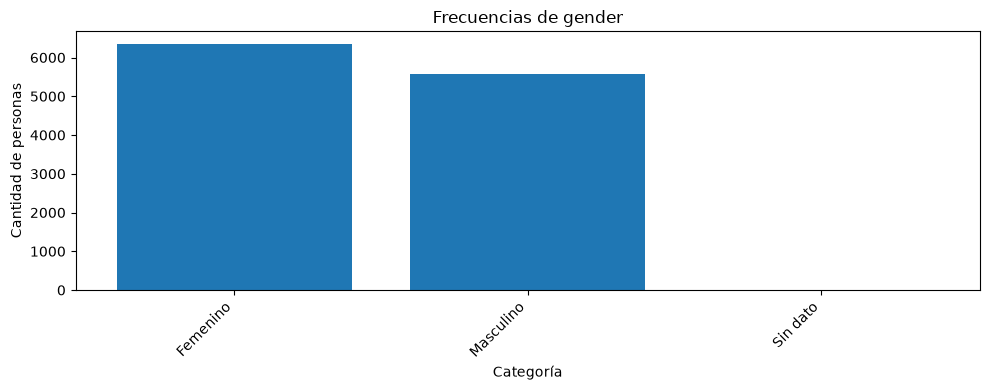

ethnicity


,Frecuencia,Porcentaje del total
ethnicity,,
Mexicano estadounidense,1117,9.36
Otro hispano,1373,11.51
Blanco no hispano,6217,52.10
Negro no hispano,1597,13.38
Asiático no hispano,681,5.71
Otro / multirracial,948,7.94
Sin dato,0,0.00


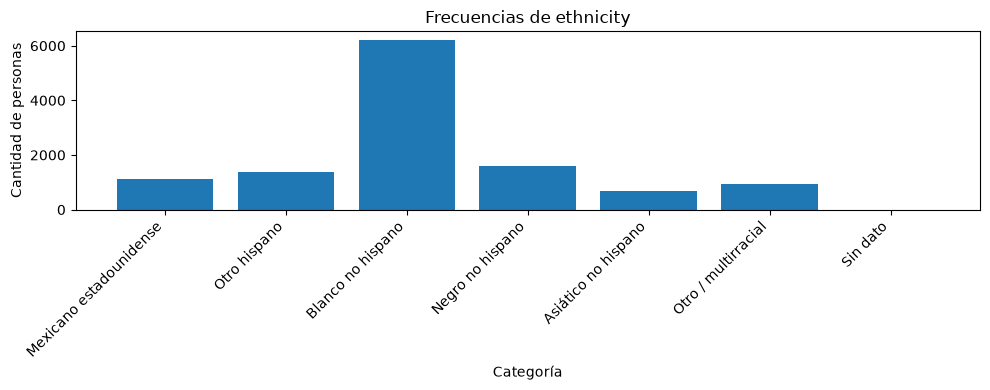

education_level


,Frecuencia,Porcentaje del total
education_level,,
Menos de noveno grado,373,3.13
Noveno a undécimo grado,666,5.58
Secundaria completa / equivalente,1749,14.66
Superior incompleto / terciario corto,2370,19.86
Universitario o superior,2625,22.00
Se negó a responder (7),0,0.00
No sabe (9),11,0.09
Sin dato,4139,34.69


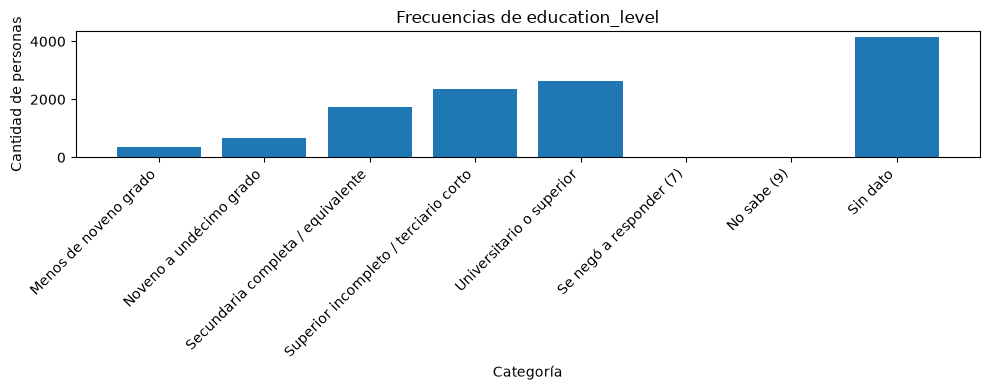

diabetes_diagnosed


,Frecuencia,Porcentaje del total
diabetes_diagnosed,,
Sí,1081,9.06
No,10371,86.91
Diagnóstico límite,284,2.38
Se negó a responder (7),0,0.00
No sabe (9),4,0.03
Sin dato,193,1.62


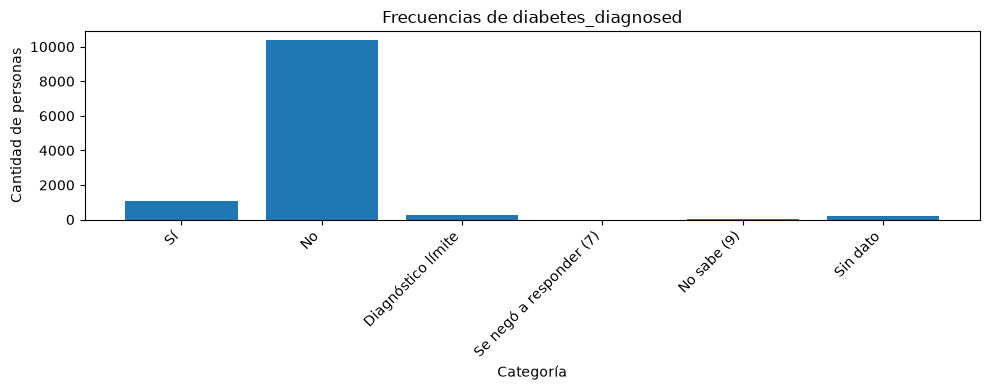

insulin_use


,Frecuencia,Porcentaje del total
insulin_use,,
Sí,344,2.88
No,737,6.18
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,10852,90.94


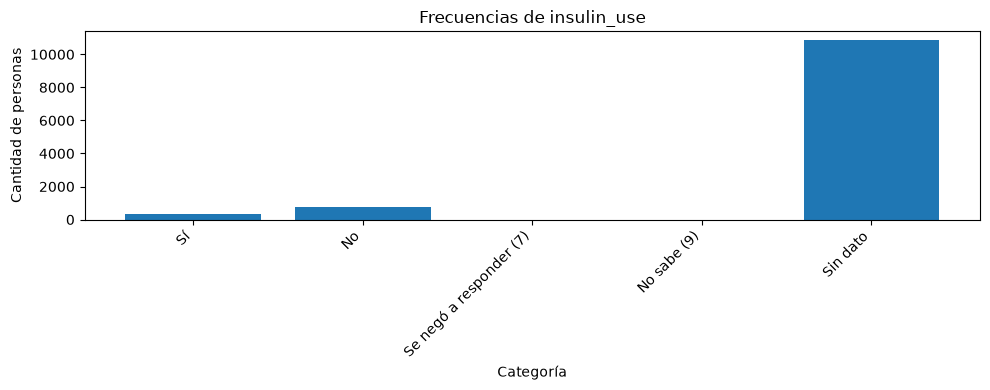

diabetes_pills


,Frecuencia,Porcentaje del total
diabetes_pills,,
Sí,885,7.42
No,1389,11.64
Se negó a responder (7),0,0.00
No sabe (9),7,0.06
Sin dato,9652,80.88


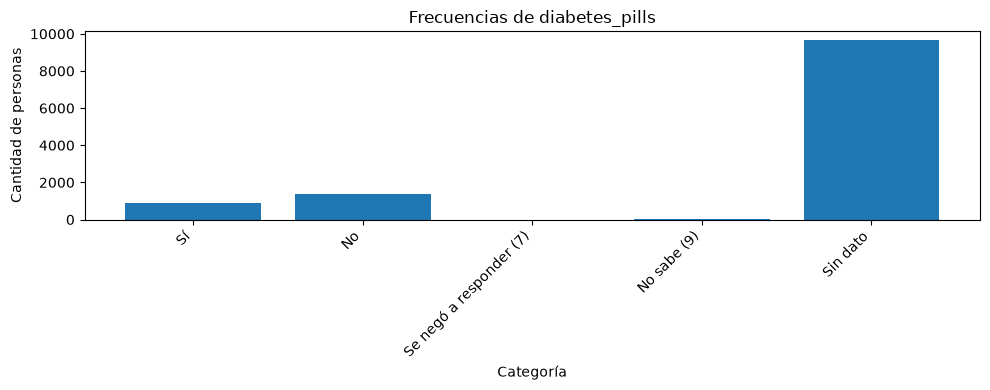

ever_smoked


,Frecuencia,Porcentaje del total
ever_smoked,,
Sí,3243,27.18
No,4878,40.88
Se negó a responder (7),7,0.06
No sabe (9),7,0.06
Sin dato,3798,31.83


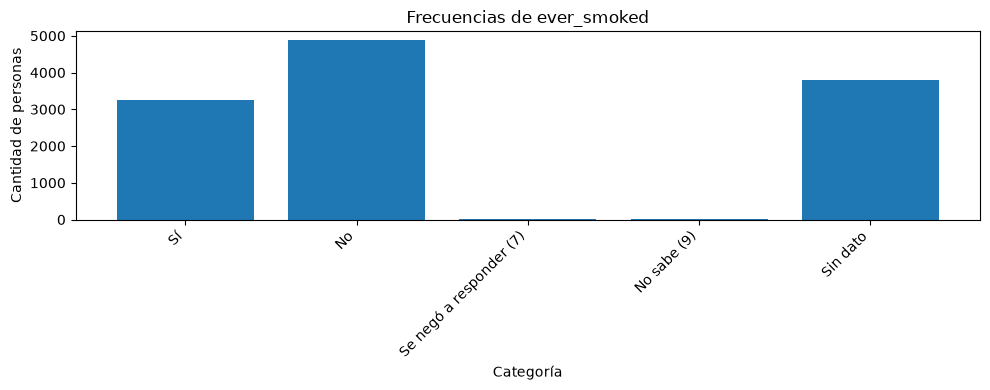

current_smoker


,Frecuencia,Porcentaje del total
current_smoker,,
Todos los días,952,7.98
Algunos días,238,1.99
Actualmente no fuma,2053,17.20
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,8690,72.82


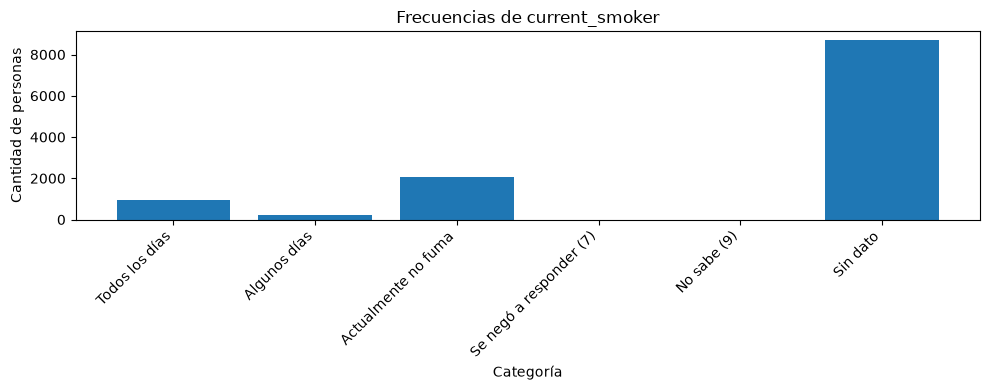

ckd_stage


,Frecuencia,Porcentaje del total
ckd_stage,,
No CKD,3592,30.10
Etapa 1,382,3.20
Etapa 2,1875,15.71
Etapa 3a,341,2.86
Etapa 3b,97,0.81
Etapa 4,28,0.23
Etapa 5,11,0.09
Etapa desconocida,5607,46.99
Sin dato,0,0.00


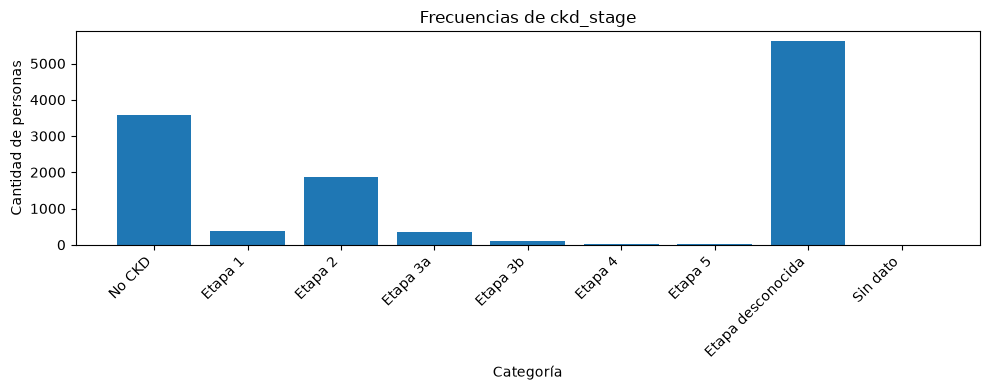

ckd_present


,Frecuencia,Porcentaje del total
ckd_present,,
Sin CKD según el archivo,3592,30.10
Con CKD según el archivo,2734,22.91
Sin dato,5607,46.99


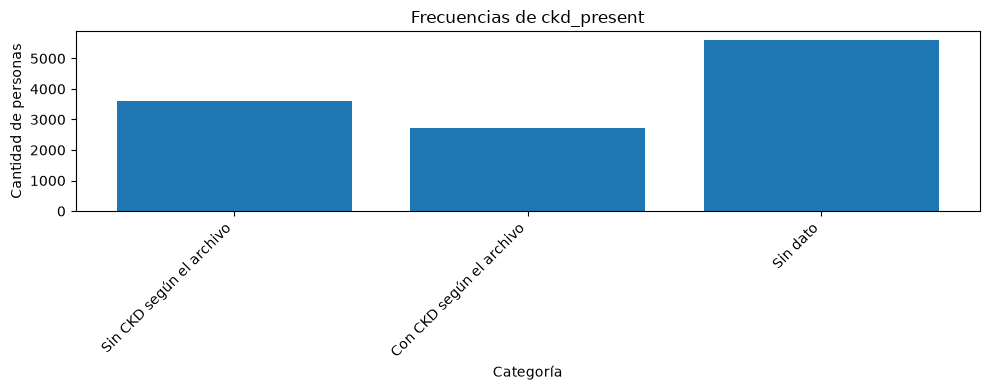

In [12]:
frecuencias_categoricas = {}

for columna, etiquetas in etiquetas_categorias.items():
    # Recuperamos los códigos de no respuesta que la conversión booleana unificó.
    if columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
        serie = df[columna].replace({
            1: "Sí", 2: "No",
            7: "Se negó a responder (7)", 9: "No sabe (9)"
        }).fillna("Sin dato")
        orden = ["Sí", "No", "Se negó a responder (7)", "No sabe (9)", "Sin dato"]
    else:
        serie = df_limpio[columna].astype("object").replace(etiquetas).fillna("Sin dato")
        orden = list(etiquetas.values()) + ["Sin dato"]

    # Conservamos también cualquier categoría que no figure en la metadata.
    serie = serie.astype(str)
    frecuencias = serie.value_counts()
    categorias_adicionales = [valor for valor in frecuencias.index if valor not in orden]
    frecuencias = frecuencias.reindex(orden + categorias_adicionales, fill_value=0)
    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje del total": (frecuencias / len(df_limpio) * 100).round(2)
    })
    frecuencias_categoricas[columna] = tabla
    print(columna)
    display(tabla)

    plt.figure(figsize=(10, 4))
    plt.bar(tabla.index, tabla["Frecuencia"])
    plt.title("Frecuencias de " + columna)
    plt.xlabel("Categoría")
    plt.ylabel("Cantidad de personas")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## 2.9. Resumen de las variables cuantitativas

`count` indica cuántos valores observados intervienen en cada resumen. Media, desvío estándar, mínimo, cuartiles, mediana y máximo se calculan sin los nulos; no se imputan valores. Los códigos de categorías y el identificador quedan fuera de estos cálculos.

Las unidades se consultan en la metadata: edad en años; peso en kg; altura en cm; BMI en kg/m²; presiones en mmHg; creatinina sérica, nitrógeno ureico, fósforo, calcio, ácido úrico y creatinina urinaria en mg/dL; albúmina sérica en g/dL; bicarbonato en mmol/L; albúmina urinaria en µg/mL; ACR en mg/g; eGFR en mL/min/1,73 m². La razón ingreso/pobreza no tiene unidad.


In [13]:
resumen_numericas = df_limpio[variables_numericas].describe().T
resumen_numericas["nulos"] = df_limpio[variables_numericas].isna().sum()
resumen_numericas["porcentaje_nulos"] = (
    df_limpio[variables_numericas].isna().mean() * 100
)
resumen_numericas.round(2)


,count,mean,std,min,25%,50%,75%,max,nulos,porcentaje_nulos
age,11933.0,38.317858,25.60199,0.0,13.0,37.0,62.0,80.0,0,0.00
poverty_income_ratio,9892.0,2.708174,1.670119,0.0,1.18,2.5,4.5,5.0,2041,17.10
bmi,8471.0,27.246665,8.137781,11.1,21.6,26.4,31.7,74.8,3462,29.01
weight_kg,8754.0,70.549037,30.389021,2.7,54.2,71.7,89.1,248.2,3179,26.64
height_cm,8499.0,159.664549,19.864943,79.1,154.4,163.6,172.1,200.7,3434,28.78
bp_systolic,7517.0,119.288546,18.561052,61.0,106.0,117.0,130.0,232.0,4416,37.01
bp_diastolic,7517.0,72.748038,11.895572,33.0,64.0,72.0,80.0,142.0,4416,37.01
serum_creatinine,6326.0,0.872828,0.385498,0.33,0.7,0.83,0.98,15.17,5607,46.99
blood_urea_nitrogen,6326.0,14.659817,5.754035,4.0,11.0,14.0,17.0,74.0,5607,46.99
albumin_serum,6366.0,4.099246,0.355161,2.2,3.9,4.1,4.3,5.5,5567,46.65


## 2.10. Distribuciones de las variables cuantitativas

Los histogramas agrupan los valores observados en 30 intervalos. Los ejes son independientes: las alturas y los rangos no deben compararse directamente entre variables con distintas cantidades de datos o unidades. Los extremos se conservan.


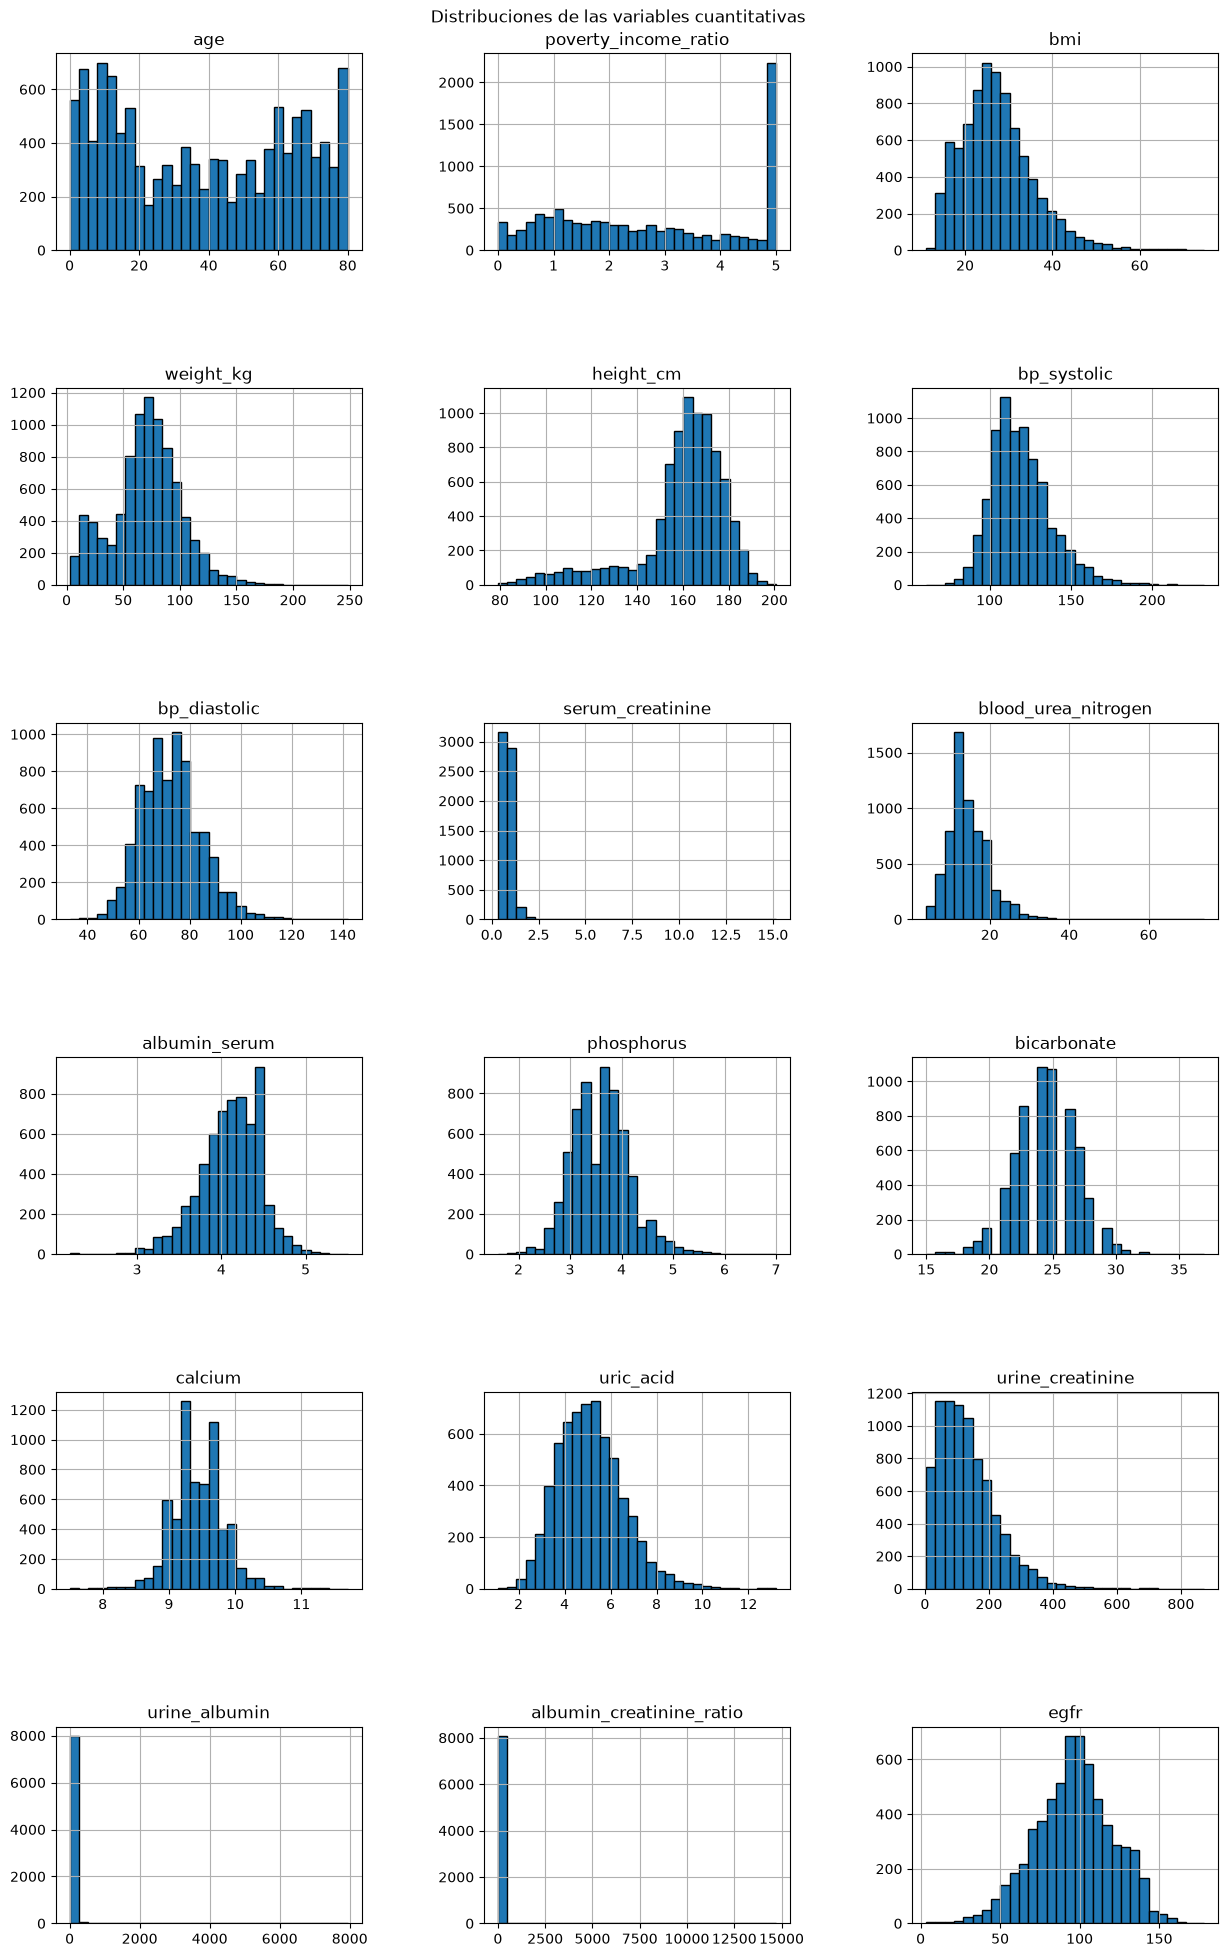

In [14]:
df_limpio[variables_numericas].hist(
    figsize=(15, 22), layout=(6, 3), bins=30, edgecolor="black"
)
plt.subplots_adjust(top=0.96, hspace=0.7, wspace=0.4)
plt.suptitle("Distribuciones de las variables cuantitativas")
plt.show()


## 2.11. Histogramas con escala ajustada

En los histogramas generales, los valores altos de `urine_albumin`, `albumin_creatinine_ratio` y `serum_creatinine` comprimen la zona donde se concentra la mayor parte de los datos. Para observar mejor sus distribuciones, agregamos histogramas con rangos acotados.

Estos gráficos muestran únicamente los valores dentro de los rangos indicados. Los valores que quedan fuera de esos rangos permanecen en el dataset; el ajuste solo cambia la visualización.


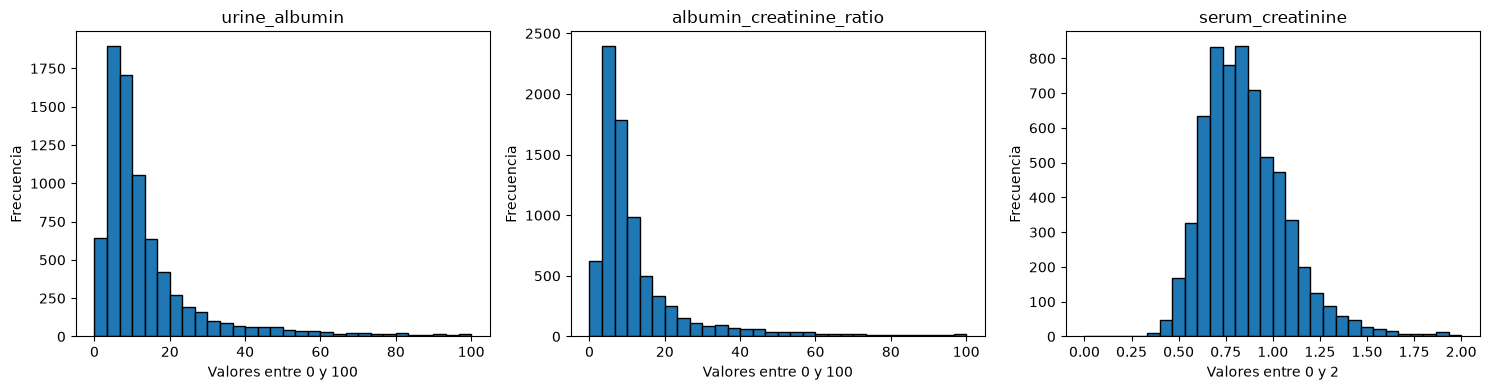

In [15]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for columna, limite, eje in zip(
    ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"],
    [100, 100, 2], ejes
):
    eje.hist(df_limpio[columna].dropna(), bins=30, range=(0, limite), edgecolor="black")
    eje.set_title(columna)
    eje.set_xlabel(f"Valores entre 0 y {limite}")
    eje.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## 2.12. Medianas, dispersión y valores extremos

Cada diagrama de caja usa su propia escala y omite los nulos. La línea central representa la mediana y la caja contiene el 50% central. Los puntos fuera de los bigotes son posibles valores extremos según la regla de 1,5 veces el rango intercuartílico; no son errores confirmados y no se eliminan.


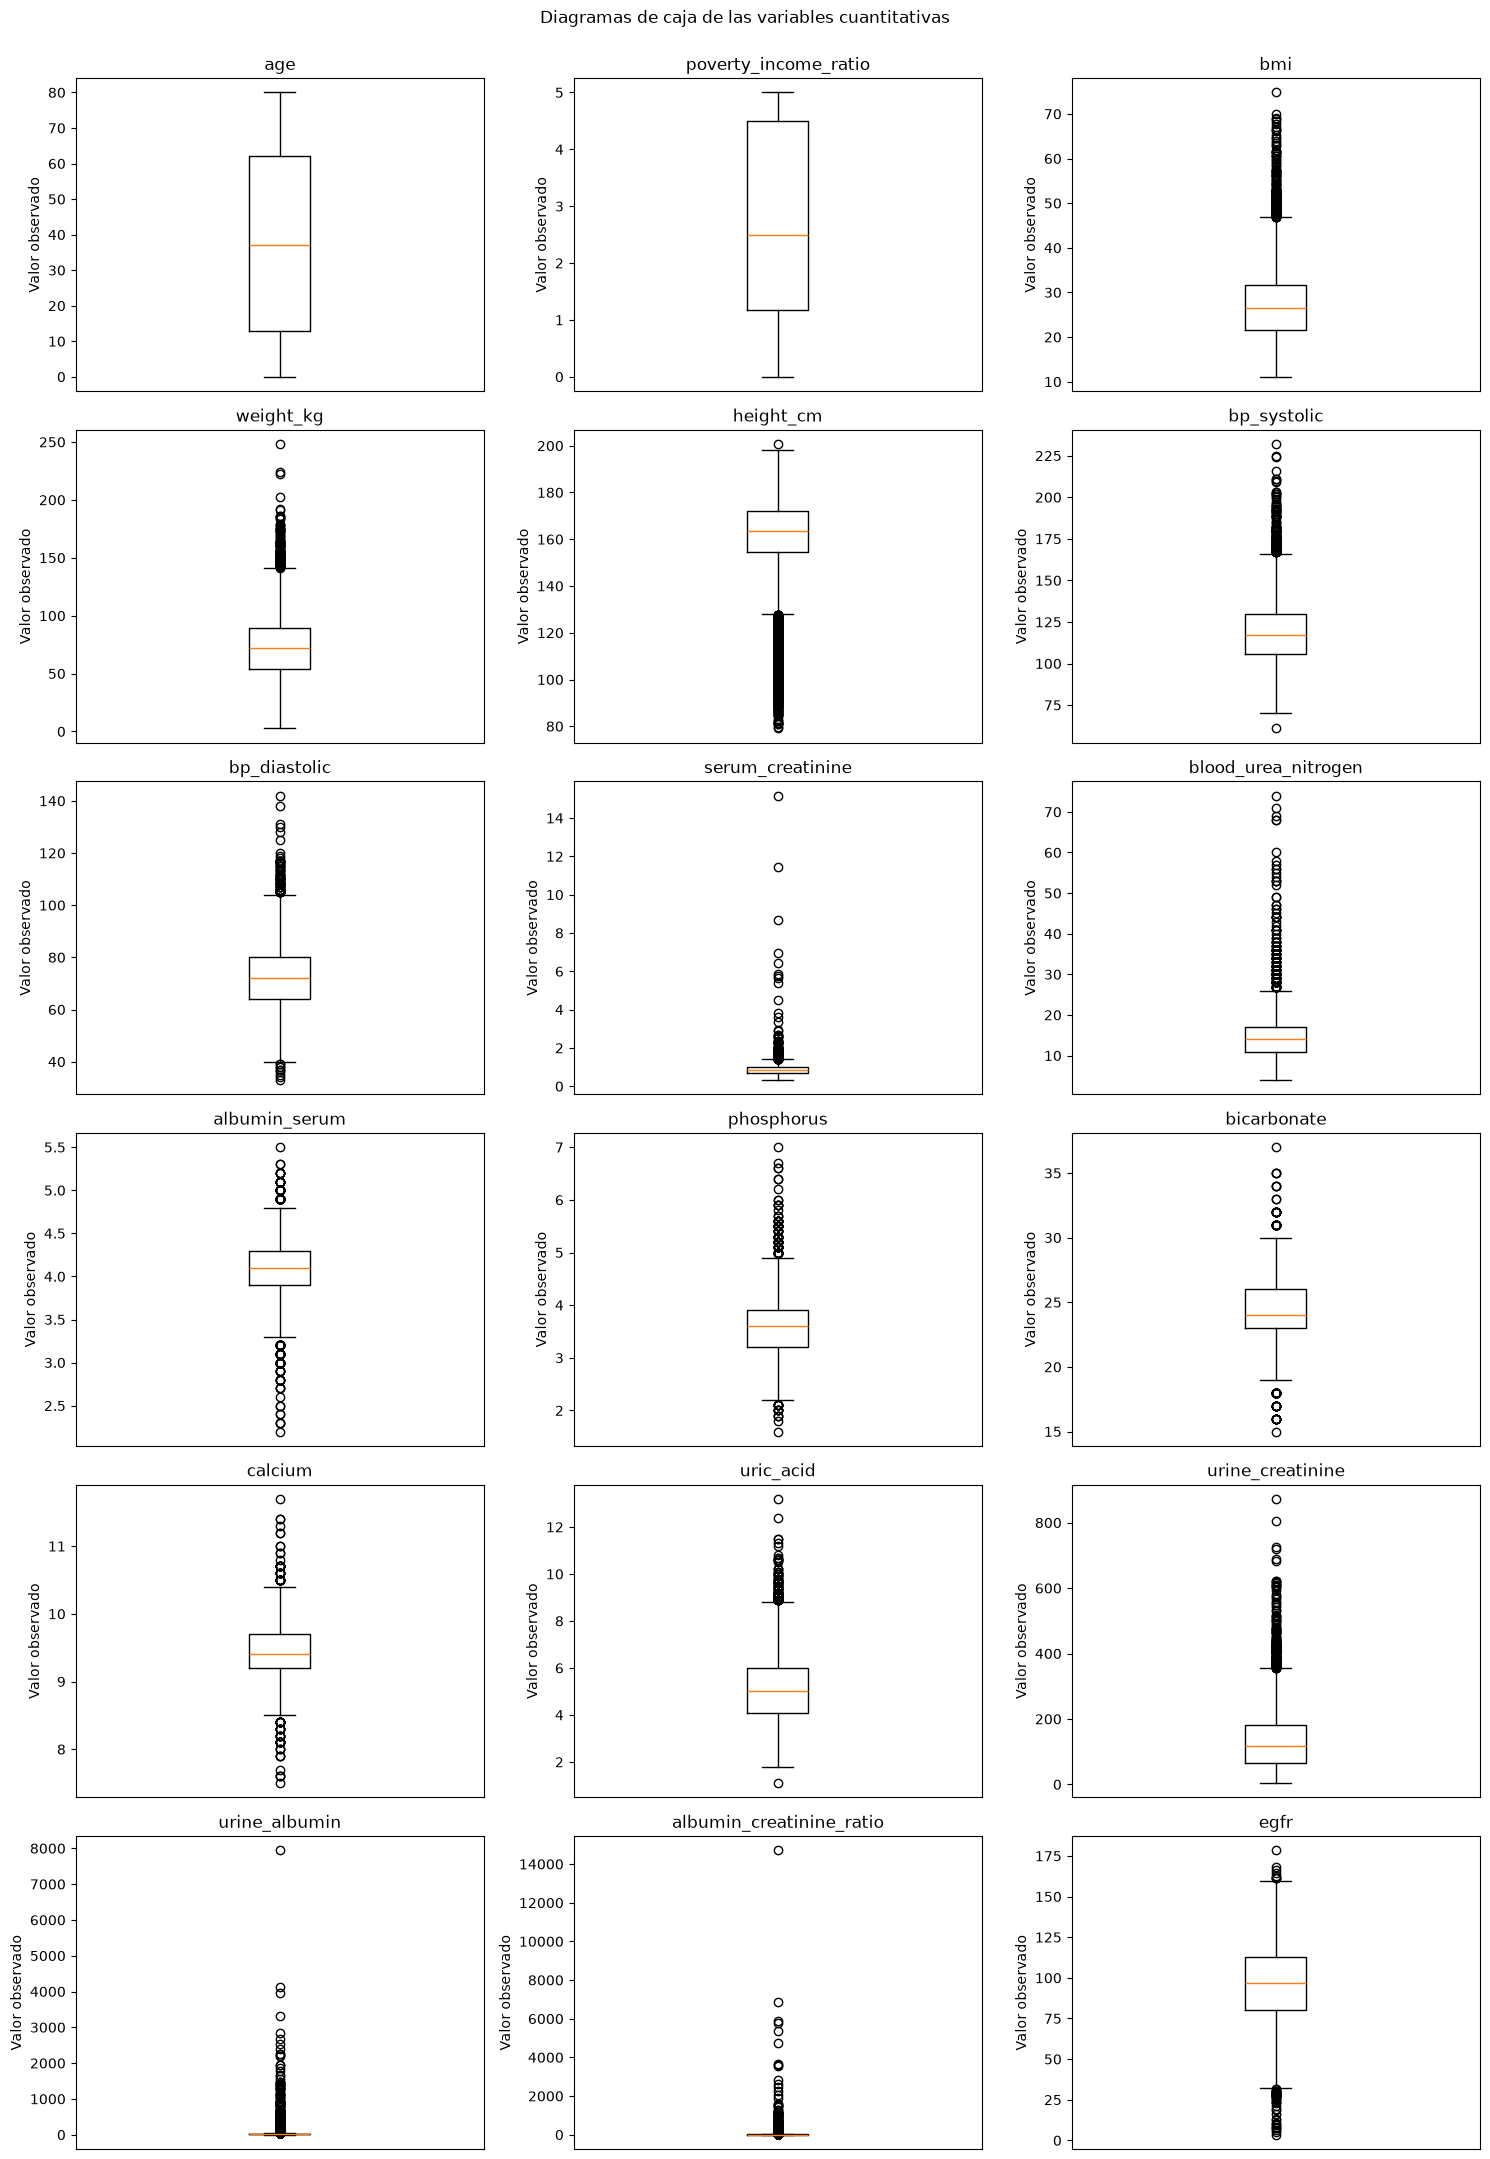

In [16]:
figura, ejes = plt.subplots(6, 3, figsize=(15, 22))

for columna, eje in zip(variables_numericas, ejes.flat):
    valores = df_limpio[columna].dropna().astype(float)
    eje.boxplot(valores)
    eje.set_title(columna)
    eje.set_xticks([])
    eje.set_ylabel("Valor observado")

figura.suptitle("Diagramas de caja de las variables cuantitativas")
figura.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


## 2.13. Filas que contienen los máximos seleccionados

Mostramos todas las filas que contienen el máximo de `urine_albumin`, `albumin_creatinine_ratio` o `serum_creatinine`. Si varias filas comparten un máximo, se muestran todas. Una fila que coincide en más de una variable aparece una sola vez.

Esta consulta permite revisar los registros completos. `df` y `df_limpio` conservan todas sus filas.


In [17]:
variables_maximos = ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"]
filas_con_maximos = pd.Series(False, index=df_limpio.index)

for columna in variables_maximos:
    maximo = df_limpio[columna].max()
    print(f"Máximo de {columna}: {maximo}")
    filas_con_maximos = filas_con_maximos | (df_limpio[columna] == maximo).fillna(False)

print("Filas que contienen alguno de los máximos:", filas_con_maximos.sum())
display(df_limpio.loc[filas_con_maximos])


Máximo de urine_albumin: 7942.47
Máximo de albumin_creatinine_ratio: 14708.28
Máximo de serum_creatinine: 15.17
Filas que contienen alguno de los máximos: 1


,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
6251,50,Male,Non-Hispanic Asian,5,1.26,27.4,79.9,170.7,139.0,71.0,15.17,52.0,3.9,6.6,23.0,8.6,7.7,54.0,7942.47,14708.28,1,True,False,True,3,3.51,Stage 5 (Kidney Failure),1


Los máximos de urine_albumin, albumin_creatinine_ratio y serum_creatinine corresponden al mismo participante. En ese registro, la relación albúmina-creatinina resulta coherente con las mediciones urinarias: 100 × 7942,47 / 54 ≈ 14708,28 mg/g, coincidiendo con el valor del dataset. Esta comprobación muestra consistencia aritmética, aunque no permite confirmar la exactitud de las mediciones. Por ese motivo, conservamos el registro y señalamos sus valores extremos para tenerlos en cuenta al interpretar los resultados.

# 3. Hipótesis y resolución

## 3.1. Hipótesis propia univariada

Planteamos que la mediana de la relación albúmina-creatinina urinaria (ACR) es menor que 30 mg/g. La metadata identifica este valor como umbral de albuminuria aumentada.

- H₀: la mediana poblacional de ACR es mayor o igual que 30 mg/g.
- H₁: la mediana poblacional de ACR es menor que 30 mg/g.

Para el análisis utilizamos los registros con ACR disponible. Este filtro incluye participantes con clasificación renal conocida y desconocida.


Comenzamos seleccionando los valores de ACR disponibles y examinamos su distribución mediante Shapiro-Wilk y un gráfico Q-Q. Como la muestra supera los 5.000 registros, tenemos en cuenta la advertencia de SciPy sobre la precisión del p-valor de Shapiro-Wilk y acompañamos su lectura con el gráfico.


In [18]:
from scipy.stats import shapiro

acr = df_limpio["albumin_creatinine_ratio"].dropna()

stat, p = shapiro(acr)
print(f"Test de Shapiro-Wilk sobre ACR: Estadístico={stat:.3f}, p-valor={p:.3f}")



Test de Shapiro-Wilk sobre ACR: Estadístico=0.070, p-valor=0.000


/home/tomas/Proyectos/ciencia_datos/TpEspecial/.venv/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8153.
  res = hypotest_fun_out(*samples, **kwds)


La distribución de ACR presenta una cola larga hacia valores altos. Para contrastar la posición de su mediana respecto de 30 mg/g utilizamos la prueba del signo mediante un test binomial.

Contamos las observaciones inferiores y superiores a 30 mg/g y excluimos los dos empates. Bajo la referencia de mediana igual a 30 para una variable continua, ambas direcciones tienen probabilidad 0,5. Como esperamos una mediana menor, contrastamos si la proporción de valores superiores a 30 es menor que 0,5. Esta prueba permite trabajar con la asimetría observada.


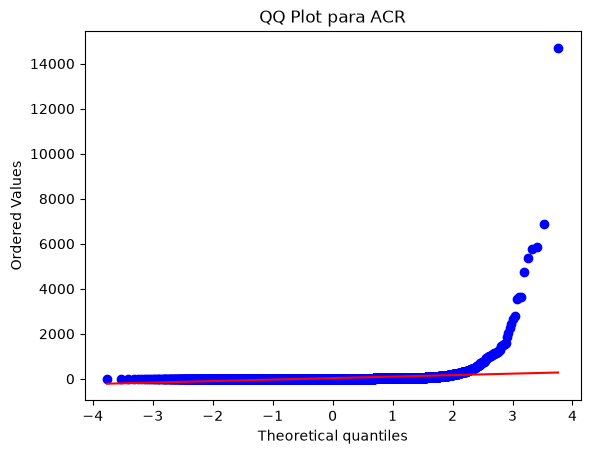

In [19]:
import matplotlib.pyplot as plt
import scipy.stats as stats

stats.probplot(acr, dist="norm", plot=plt)
plt.title("QQ Plot para ACR")
plt.show()

In [ ]:
# Prueba del Signo para la mediana (H0: Mediana >= 30 vs H1: Mediana < 30)
menores_30 = int((acr < 30).sum())
mayores_30 = int((acr > 30).sum())
n_validos = menores_30 + mayores_30

# Si la mediana fuera 30, la probabilidad de superar 30 seria p = 0.5
res_signo = stats.binomtest(mayores_30, n=n_validos, p=0.5, alternative="less")

In [21]:
print(f"Mediana de ACR: {acr.median():.2f} mg/g | Media de ACR: {acr.mean():.2f} mg/g")
print(f"Casos con ACR < 30: {menores_30} ({menores_30/n_validos*100:.2f}%) | Casos con ACR > 30: {mayores_30} ({mayores_30/n_validos*100:.2f}%)")
print(f"Prueba del Signo (binomtest, mediana < 30): p-valor = {res_signo.pvalue:.4e}")

Mediana de ACR: 8.27 mg/g | Media de ACR: 33.36 mg/g
Casos con ACR < 30: 7144 (87.65%) | Casos con ACR > 30: 1007 (12.35%)
Prueba del Signo (binomtest, mediana < 30): p-valor = 0.0000e+00


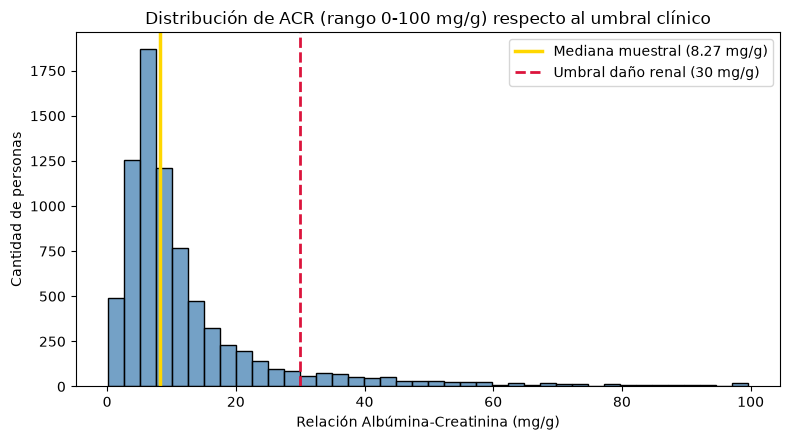

In [ ]:
# visualización (Histograma acotado + líneas de referencia)
plt.figure(figsize=(8, 4.5))
sns.histplot(acr[acr <= 100], bins=40, color="steelblue", edgecolor="black")
plt.axvline(acr.median(), color="gold", linewidth=2.5, label=f"Mediana muestral ({acr.median():.2f} mg/g)")
plt.axvline(30, color="crimson", linestyle="--", linewidth=2, label="Umbral daño renal (30 mg/g)")
plt.title("Distribución de ACR (rango 0-100 mg/g) respecto al umbral clínico")
plt.xlabel("Relación Albúmina-Creatinina (mg/g)")
plt.ylabel("Cantidad de personas")
plt.legend()
plt.tight_layout()
plt.show()

La mediana muestral de ACR es 8,27 mg/g y la media es 33,36 mg/g. La diferencia entre ambas medidas refleja la influencia de la cola de valores altos.

De las 8.153 observaciones con ACR disponible, dos son iguales a 30 mg/g y se excluyen del contraste. Entre las 8.151 restantes, 7.144 son inferiores a 30 mg/g (87,65 %) y 1.007 son superiores (12,35 %).

La prueba binomial produce un p-valor menor que 0,001. El cero mostrado en la salida corresponde a precisión numérica.

**Con α = 0,05, rechazamos H₀ y encontramos evidencia a favor de una mediana de ACR menor que 30 mg/g.**

El contraste se interpreta bajo el supuesto de observaciones independientes. Los resultados corresponden a los registros con ACR disponible y se calcularon sin ponderaciones de la encuesta.


## 3.2. Hipótesis propia bivariada

Hipótesis: La presencia de enfermedad renal crónica (ckd_present) está asociada con el diagnóstico declarado de diabetes (diabetes_diagnosed). Se espera observar una proporción mayor de ERC entre quienes declararon diabetes o diagnóstico límite. Elegimos esta hipótesis porque la metadata identifica a la diabetes como un factor relacionado con el deterioro renal.

H0: La presencia de ERC y el diagnóstico de diabetes son estadísticamente independientes.
H1: Existe asociación estadística entre el diagnóstico de diabetes y la presencia de ERC.

Para el test, analizamos que ambas variables son cualitatativas, codificadas. y como estamos chequeado independencia de 2 cualitativas debemos utilizar chi cuadrado mediante la comparacion de frecuencias obtenidas con frecuencias esperadas.

Para comenzar realizamos un fitrado de los codigos validos de de diabetes, los cuales eran: 1(si) 2(no) 3(diagnostico limite), quitamos los valores nulos de ckd_present, mapeamos los codigos a categorias legibles para que lo entendamos mejor.

In [23]:
#filtrado
df_renal = df_limpio.dropna(subset=["ckd_present"]).copy()
df_renal["ckd_present"] = df_renal["ckd_present"].astype(int)
df_diab = df_renal[df_renal["diabetes_diagnosed"].isin([1, 2, 3])].copy()


#utilizamos un diccionario para traducir los numeros a etiquetas y las guardamos en una nueva columna llamada diabetes_cat 
mapeo_diabetes = {1: "Sí", 2: "No", 3: "Diagnóstico límite"}
df_diab["diabetes_cat"] = df_diab["diabetes_diagnosed"].map(mapeo_diabetes)


#construimos la tabla de contigencia con pandas
tabla_contingencia = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"])

# aplicamos el chi-cuadrado a la tabla de contungencia armada, en chi2 guardamos el valor del estadistico, en p_val el pvalor, en dof los grados de libertad (que recordamos que se calculan como filas-1, col-1)
# y en ex queda la matriz de frecuencias esperadas
chi2, p_val_chi2, dof, ex = stats.chi2_contingency(tabla_contingencia)


# y volvemos a hacer un pd.crosstab para armar una segunda tabla pero con porcentajes sumados por fila para estandarizarlos
proporciones_diab = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"], normalize="index") * 100


print("Tabla de contingencia (frecuencias obtenidas):\n", tabla_contingencia)
print("\nPrevalencia por fila (%):\n", proporciones_diab.round(2))
print(f"\nChi-cuadrado: {chi2:.2f}, gl: {dof}, p-valor: {p_val_chi2:.4e}\n")

Tabla de contingencia (frecuencias obtenidas):
 ckd_present            0     1
diabetes_cat                  
Diagnóstico límite    99   104
No                  3228  2128
Sí                   264   502

Prevalencia por fila (%):
 ckd_present             0      1
diabetes_cat                    
Diagnóstico límite  48.77  51.23
No                  60.27  39.73
Sí                  34.46  65.54

Chi-cuadrado: 187.31, gl: 2, p-valor: 2.1233e-41



El p-valor obtenido es menor que 0,05, por lo que rechazamos la hipótesis nula de independencia. Los resultados respaldan una asociación estadística entre el diagnóstico declarado de diabetes y la presencia de ERC en los registros analizados.

### Planteo y análisis de la hipótesis propia multivariada

Planteamos que, entre los participantes adultos analizados, los perfiles definidos conjuntamente por edad, IMC y presión arterial presentan distintas proporciones de CKD. Esperamos observar la mayor proporción en el perfil caracterizado por mayor edad y presión sistólica.

Para abordar la hipótesis seguimos estos pasos:

1. Seleccionamos participantes de 18 años o más con datos completos y examinamos las correlaciones entre edad, IMC y ambas presiones.
2. Estandarizamos las variables elegidas y construimos perfiles mediante K-Means. Comparamos valores de k con la inercia y el coeficiente de silueta.
3. Caracterizamos los perfiles en sus unidades originales y utilizamos PCA para representarlos en dos dimensiones.
4. Comparamos los perfiles con ckd_present mediante una tabla de contingencia y chi-cuadrado de independencia. El contraste evalúa diferencias globales entre las proporciones. Los porcentajes por perfil permiten identificar cuál presenta la mayor proporción observada.


Filtramos los participantes adultos (18 años o mas) que tengan datos completos en edad, BMI, presion arterial y diagnostico de CKD, y calculamos la matriz de correlacion entre las variables cuantitativas.

Cantidad de participantes adultos con datos completos: 5438


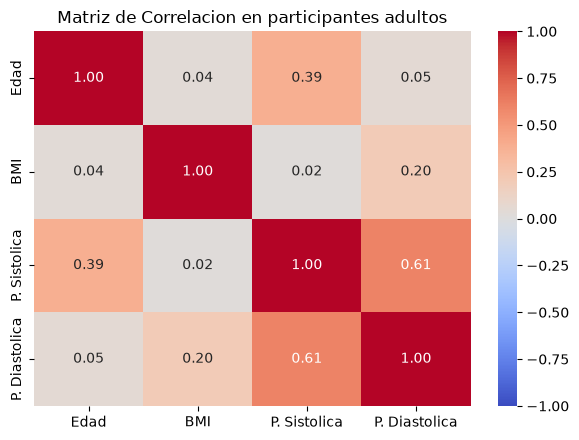

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# filtramos participantes adultos (age >= 18) sin nulos en las variables de interes
vars_iniciales = ["age", "bmi", "bp_systolic", "bp_diastolic"]
df_adultos = df_limpio[df_limpio["age"] >= 18].dropna(subset=vars_iniciales + ["ckd_present"]).copy()
df_adultos["ckd_present"] = df_adultos["ckd_present"].astype(int)

print("Cantidad de participantes adultos con datos completos:", len(df_adultos))

# calculamos y graficamos la matriz de correlacion de las variables cuantitativas
corr_adultos = df_adultos[vars_iniciales].astype(float).corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    corr_adultos, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
    xticklabels=["Edad", "BMI", "P. Sistolica", "P. Diastolica"],
    yticklabels=["Edad", "BMI", "P. Sistolica", "P. Diastolica"]
)
plt.title("Matriz de Correlacion en participantes adultos")
plt.tight_layout()
plt.show()

La correlación entre presión sistólica y diastólica es aproximadamente 0,61. Para reducir la representación redundante de la presión en las distancias de K-Means, elegimos edad, IMC y presión sistólica como variables para construir los perfiles.

Estandarizamos estas tres variables con StandardScaler para que sus distintas unidades no dominen el cálculo de distancias. Luego probamos valores de k entre 2 y 6 y comparamos la inercia y la silueta media.


,k,Inercia (WSS),Silueta media
0,2,11146.6,0.307
1,3,8398.9,0.318
2,4,6620.4,0.300
3,5,5937.0,0.285
4,6,5365.6,0.261


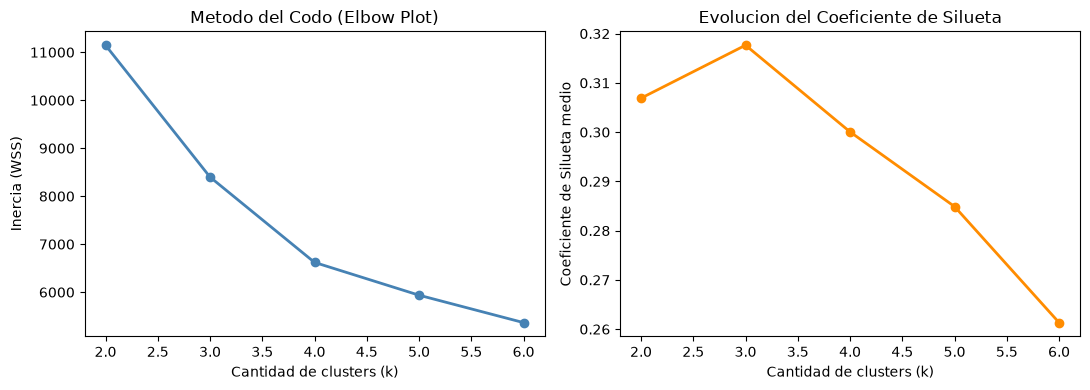

In [25]:
vars_perfil = ["age", "bmi", "bp_systolic"]
nombres_perfil = ["Edad", "BMI", "Presion Sistolica"]

X_adultos = df_adultos[vars_perfil].astype(float)

# estandarizamos las variables para que tengan media 0 y desvio 1
scaler_cluster = StandardScaler()
X_adultos_stand = scaler_cluster.fit_transform(X_adultos)

# probamos K-Means con k de 2 a 6 guardando la inercia y la silueta media
valores_k = range(2, 7)
inercias = []
siluetas = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=10, n_init=10)
    etiquetas = km.fit_predict(X_adultos_stand)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_adultos_stand, etiquetas))

tabla_k = pd.DataFrame({
    "k": list(valores_k),
    "Inercia (WSS)": np.round(inercias, 1),
    "Silueta media": np.round(siluetas, 3)
})
display(tabla_k)

# graficamos el Elbow plot y el Coeficiente de Silueta
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(valores_k, inercias, marker="o", color="steelblue", linewidth=2)
ejes[0].set_xlabel("Cantidad de clusters (k)")
ejes[0].set_ylabel("Inercia (WSS)")
ejes[0].set_title("Metodo del Codo (Elbow Plot)")

ejes[1].plot(valores_k, siluetas, marker="o", color="darkorange", linewidth=2)
ejes[1].set_xlabel("Cantidad de clusters (k)")
ejes[1].set_ylabel("Coeficiente de Silueta medio")
ejes[1].set_title("Evolucion del Coeficiente de Silueta")

plt.tight_layout()
plt.show()

Entre los valores evaluados, k = 3 obtiene la mayor silueta media (0,318), con una inercia de 8.398,9. Elegimos tres perfiles considerando ambos criterios. El valor de silueta indica que los grupos presentan cierto solapamiento.

Ajustamos K-Means con k = 3, describimos los perfiles mediante medias, medianas y diagramas de caja, y los representamos en el plano de las dos primeras componentes principales.


Caracterizacion de los 3 perfiles en sus unidades originales:


age                 bmi         \
                                           count   mean median count   mean   
perfil_nombre                                                                 
Perfil 0: Mayor edad y P. Sistolica alta    2382  66.85   67.0  2382  27.69   
Perfil 1: Edad media y BMI alto (Obesidad)  1130   51.5   53.0  1130  39.82   
Perfil 2: Jovenes con presion y BMI bajos   1926  35.85   35.0  1926  25.87   

                                                  bp_systolic                 
                                           median       count    mean median  
perfil_nombre                                                                 
Perfil 0: Mayor edad y P. Sistolica alta     27.6        2382  133.34  131.0  
Perfil 1: Edad media y BMI alto (Obesidad)   38.6        1130  117.76  117.0  
Perfil 2: Jovenes con presion y BMI bajos    25.7        1926  111.32  111.0

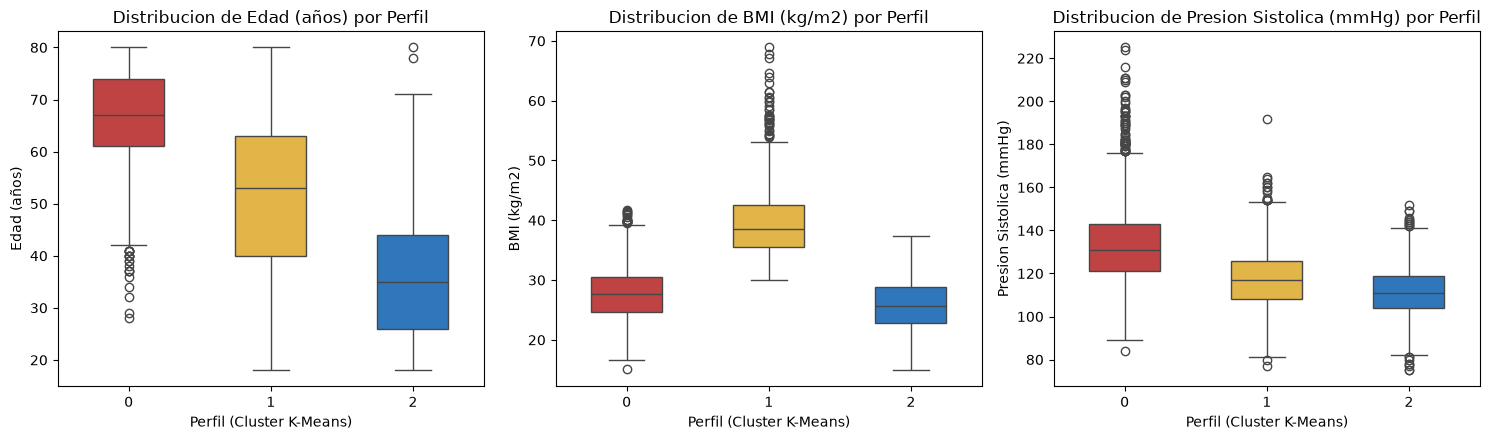

In [26]:
# ajustamos K-Means con el k = 3 seleccionado
kmeans_final = KMeans(n_clusters=3, random_state=10, n_init=10)
df_adultos["cluster"] = kmeans_final.fit_predict(X_adultos_stand)

# le ponemos nombres descriptivos a cada perfil segun sus valores medios para que se entienda mejor
mapeo_perfiles = {
    0: "Perfil 0: Mayor edad y P. Sistolica alta",
    1: "Perfil 1: Edad media y BMI alto (Obesidad)",
    2: "Perfil 2: Jovenes con presion y BMI bajos"
}
df_adultos["perfil_nombre"] = df_adultos["cluster"].map(mapeo_perfiles)

resumen_perfiles = df_adultos.groupby("perfil_nombre")[vars_perfil].agg(["count", "mean", "median"]).round(2)
print("Caracterizacion de los 3 perfiles en sus unidades originales:")
display(resumen_perfiles)

# graficamos los boxplots de las 3 variables por perfil en unidades originales 
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
orden_perfiles = [
    "Perfil 0: Mayor edad y P. Sistolica alta",
    "Perfil 1: Edad media y BMI alto (Obesidad)",
    "Perfil 2: Jovenes con presion y BMI bajos"
]
colores_perf = ["#d32f2f", "#fbc02d", "#1976d2"]

for ax, col, titulo in zip(ejes, vars_perfil, ["Edad (años)", "BMI (kg/m2)", "Presion Sistolica (mmHg)"]):
    sns.boxplot(
        data=df_adultos, x="cluster", y=col, hue="cluster", ax=ax,
        palette=colores_perf, width=0.5, legend=False
    )
    ax.set_title(f"Distribucion de {titulo} por Perfil")
    ax.set_xlabel("Perfil (Cluster K-Means)")
    ax.set_ylabel(titulo)

plt.tight_layout()
plt.show()

Varianza explicada por PC1: 46.4% | PC2: 33.2% | Acumulada (2D): 79.6%


,Edad,BMI,Presion Sistolica
PC1,0.704,0.103,0.702
PC2,-0.052,0.994,-0.094


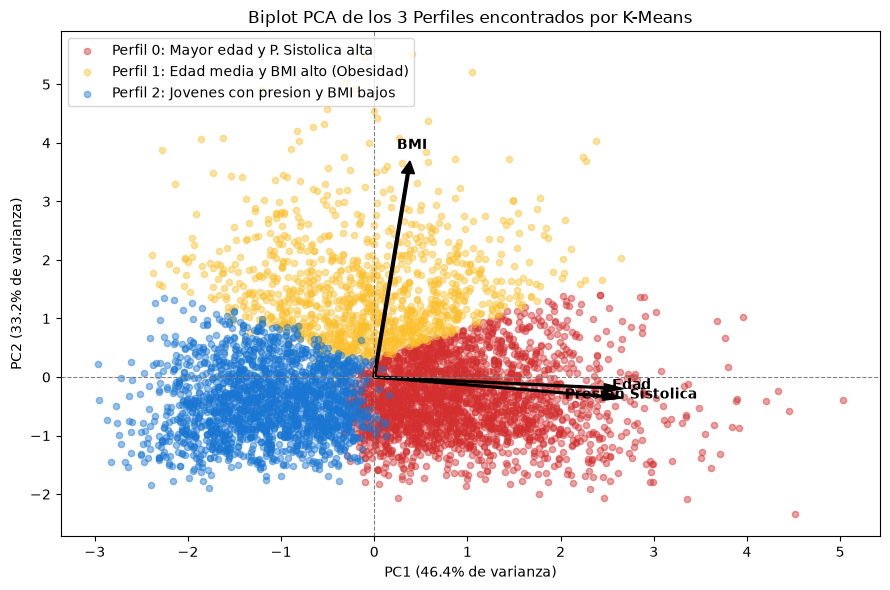

In [27]:
# representamos los 3 perfiles en 2 dimensiones usando PCA y Biplot 
pca_perfiles = PCA()
coords_pca = pca_perfiles.fit_transform(X_adultos_stand)
var_exp_perf = pca_perfiles.explained_variance_ratio_

print(f"Varianza explicada por PC1: {var_exp_perf[0]*100:.1f}% | PC2: {var_exp_perf[1]*100:.1f}% | Acumulada (2D): {(var_exp_perf[0]+var_exp_perf[1])*100:.1f}%")

cargas_perf = pd.DataFrame(
    pca_perfiles.components_[:2],
    columns=nombres_perfil,
    index=["PC1", "PC2"]
)
display(cargas_perf.round(3))

plt.figure(figsize=(9, 6))
for cluster_id, color, etiqueta in zip([0, 1, 2], colores_perf, orden_perfiles):
    mask = (df_adultos["cluster"] == cluster_id).values
    plt.scatter(
        coords_pca[mask, 0], coords_pca[mask, 1],
        c=color, label=etiqueta, alpha=0.45, s=20
    )

# dibujamos los vectores de las variables originales sobre el plano del PCA
escala = 3.5
for i, nombre in enumerate(nombres_perfil):
    dx = pca_perfiles.components_[0, i] * escala
    dy = pca_perfiles.components_[1, i] * escala
    plt.arrow(0, 0, dx, dy, color="black", width=0.03, head_width=0.14)
    plt.text(dx * 1.12, dy * 1.12, nombre, color="black", fontsize=10, fontweight="bold", ha="center")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel(f"PC1 ({var_exp_perf[0]*100:.1f}% de varianza)")
plt.ylabel(f"PC2 ({var_exp_perf[1]*100:.1f}% de varianza)")
plt.title("Biplot PCA de los 3 Perfiles encontrados por K-Means")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Las dos primeras componentes principales explican el 79,6 % de la varianza de las tres variables estandarizadas. PC1 explica el 46,4 % y combina principalmente edad y presión sistólica, con pesos de 0,704 y 0,702. PC2 explica el 33,2 % y está principalmente vinculada con el IMC, con un peso de 0,994.

Esta representación permite interpretar la separación de los perfiles. El perfil 0 presenta las mayores medianas de edad y sistólica, mientras que el perfil 1 presenta la mayor mediana de IMC. El perfil 2 reúne participantes más jóvenes, con valores menores de sistólica e IMC respecto de los otros perfiles.

Una vez construidos los grupos con las variables clínicas, los cruzamos con ckd_present y aplicamos chi-cuadrado de independencia.

- H₀: la proporción de CKD es igual en los tres perfiles.
- H₁: existe alguna diferencia entre las proporciones de CKD de los perfiles.


Tabla de contingencia (Frecuencias observadas por perfil):


ckd_present,0,1
perfil_nombre,,
Perfil 0: Mayor edad y P. Sistolica alta,744,1638
Perfil 1: Edad media y BMI alto (Obesidad),615,515
Perfil 2: Jovenes con presion y BMI bajos,1529,397


Proporcion de CKD dentro de cada perfil (% por fila):


ckd_present,0,1
perfil_nombre,,
Perfil 0: Mayor edad y P. Sistolica alta,31.23,68.77
Perfil 1: Edad media y BMI alto (Obesidad),54.42,45.58
Perfil 2: Jovenes con presion y BMI bajos,79.39,20.61


Resultado del Test Chi-cuadrado: Chi2 = 992.54, gl = 2, p-valor = 2.9751e-216


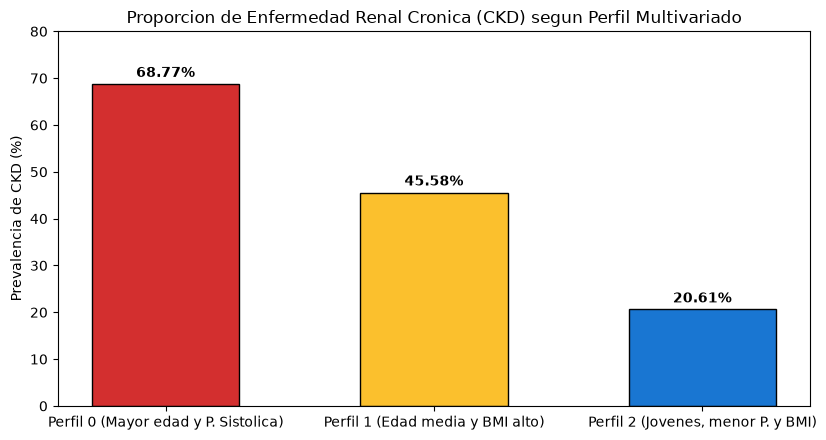

In [28]:
# construimos la tabla de contingencia entre los perfiles y ckd_present
tabla_cont_perfiles = pd.crosstab(df_adultos["perfil_nombre"], df_adultos["ckd_present"])
tabla_prop_perfiles = pd.crosstab(df_adultos["perfil_nombre"], df_adultos["ckd_present"], normalize="index") * 100

print("Tabla de contingencia (Frecuencias observadas por perfil):")
display(tabla_cont_perfiles)

print("Proporcion de CKD dentro de cada perfil (% por fila):")
display(tabla_prop_perfiles.round(2))

# aplicamos el Test Chi-cuadrado
chi2_perf, p_val_perf, dof_perf, esp_perf = stats.chi2_contingency(tabla_cont_perfiles)
print(f"Resultado del Test Chi-cuadrado: Chi2 = {chi2_perf:.2f}, gl = {dof_perf}, p-valor = {p_val_perf:.4e}")

# graficamos la proporcion de CKD en cada perfil
plt.figure(figsize=(8.5, 4.5))
etiquetas_barras = [
    "Perfil 0 (Mayor edad y P. Sistolica)",
    "Perfil 1 (Edad media y BMI alto)",
    "Perfil 2 (Jovenes, menor P. y BMI)"
]
barras_perf = plt.bar(
    etiquetas_barras,
    tabla_prop_perfiles[1].values,
    color=colores_perf, edgecolor="black", width=0.55
)

for b in barras_perf:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 1.5, f"{h:.2f}%", ha="center", fontweight="bold")

plt.ylabel("Prevalencia de CKD (%)")
plt.title("Proporcion de Enfermedad Renal Cronica (CKD) segun Perfil Multivariado")
plt.ylim(0, 80)
plt.tight_layout()
plt.show()

El contraste produjo χ² = 992,54, con 2 grados de libertad y p = 2,98 × 10⁻²¹⁶. Como p < 0,05, rechazamos la hipótesis de independencia.

**Los resultados respaldan una asociación global entre los perfiles multivariados y la presencia de CKD en los adultos analizados.**

El perfil 0, con medianas de 67 años y 131 mmHg de presión sistólica, presentó la mayor proporción observada de CKD (68,77 %). Las proporciones fueron 45,58 % en el perfil 1 y 20,61 % en el perfil 2.

La dirección de estos porcentajes coincide con lo planteado en la hipótesis. Para establecer cuáles pares de perfiles difieren significativamente serían necesarias comparaciones adicionales. Los grupos se construyeron y evaluaron en la misma muestra, por lo que su generalización requiere validación en otros datos.


## 3.3. Hipótesis univariada planteada por la cátedra

La hipótesis plantea que la mayoría de los casos identificados de CKD corresponde a personas blancas no hispánicas. Filtramos los registros con CKD y estudiamos la distribución de la etnia dentro de ese conjunto.

- H₀: la proporción de blancos no hispánicos entre los casos es como máximo 50 %.
- H₁: esa proporción es mayor que 50 %.

El código aplica chi-cuadrado de bondad de ajuste frente a un reparto 50/50 entre blancos no hispánicos y el resto. Este contraste detecta diferencias en ambas direcciones. Para interpretar la hipótesis de mayoría también observamos si la proporción muestral supera el 50 %.


Total de casos de CKD identificados: 2734



,Frecuencia Observada,Porcentaje (%)
ethnicity,,
Non-Hispanic White,1741,63.68
Non-Hispanic Black,377,13.79
Other Hispanic,235,8.60
Other/Multiracial,169,6.18
Mexican American,118,4.32
Non-Hispanic Asian,94,3.44



Proporción muestral de Blancos no-hispánicos (p̂): 0.6368 (63.68%)
Frecuencias observadas [Blancos NH, Resto]: [np.int64(1741), np.int64(993)] | Esperadas (50/50): [1367.0, 1367.0]
Test Chi-cuadrado de bondad de ajuste: Chi2 = 204.6467, p-valor = 2.0225e-46


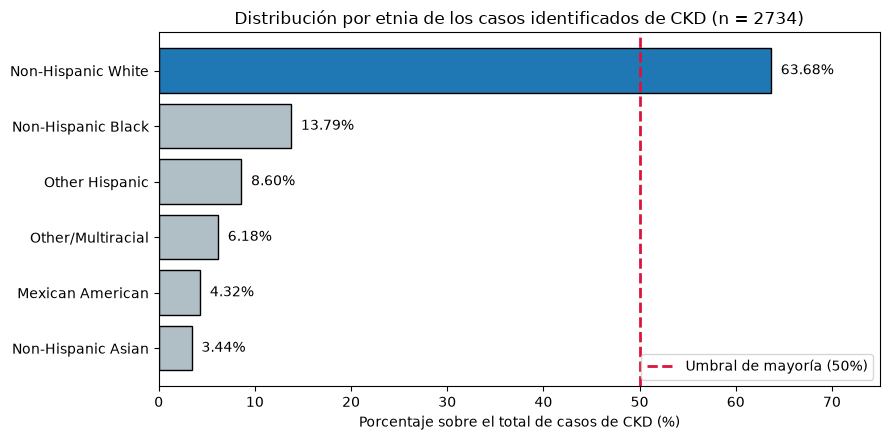

In [29]:
# filtramos los casos con CKD
df_ckd = df_limpio[df_limpio["ckd_present"] == 1].dropna(subset=["ethnicity"]).copy()

# con los datos de los de ckd, construimos la tabla de frecuencias absolutas y realtivas, con value conts contamos cuantos pacientes pertenecen a cada etinia y obtenemos las absolutas, y cuando lo normalizamos obtenemos la relativas
n_ckd = len(df_ckd)
frec_abs = df_ckd["ethnicity"].value_counts()
frec_rel = (df_ckd["ethnicity"].value_counts(normalize=True) * 100).round(2)

tabla_etnias_ckd = pd.DataFrame({
    "Frecuencia Observada": frec_abs,
    "Porcentaje (%)": frec_rel
})
print(f"Total de casos de CKD identificados: {n_ckd}\n")
display(tabla_etnias_ckd)

# 3. Aca tenemos los datos para el contraste de una proporcion, blancos no-hispanicos contra el resto, tambien calculamos la poblacion muestral observada y establecemos el umbral de mayoria en 50%
k_blancos = frec_abs["Non-Hispanic White"]
k_resto = n_ckd - k_blancos
p_hat = k_blancos / n_ckd
p_0 = 0.50  


# Aplicamps el Test Chi-cuadrado de bondad de ajuste (frecuencias observadas vs esperadas 50/50), multiplicamos la cantidad por el umbral que decidimos 50% y utilizamos ese para las esperdas
frec_obs_bin = [k_blancos, k_resto]
frec_esp_bin = [n_ckd * p_0, n_ckd * (1 - p_0)]
chi2_gof, p_valor_chi2 = stats.chisquare(f_obs=frec_obs_bin, f_exp=frec_esp_bin)

print(f"\nProporción muestral de Blancos no-hispánicos (p̂): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Frecuencias observadas [Blancos NH, Resto]: {frec_obs_bin} | Esperadas (50/50): {frec_esp_bin}")

print(f"Test Chi-cuadrado de bondad de ajuste: Chi2 = {chi2_gof:.4f}, p-valor = {p_valor_chi2:.4e}")


plt.figure(figsize=(9, 4.5))
colores = ["#1f77b4" if etnia == "Non-Hispanic White" else "#b0bec5" for etnia in frec_rel.index]
barras = plt.barh(frec_rel.index[::-1], frec_rel.values[::-1], color=colores[::-1], edgecolor="black")

plt.axvline(50, color="crimson", linestyle="--", linewidth=2, label="Umbral de mayoría (50%)")
plt.xlabel("Porcentaje sobre el total de casos de CKD (%)")
plt.title("Distribución por etnia de los casos identificados de CKD (n = 2734)")
plt.xlim(0, 75)

for barra in barras:
    ancho = barra.get_width()
    plt.text(ancho + 1, barra.get_y() + barra.get_height()/2, f"{ancho:.2f}%", va="center", fontsize=10)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Entre los 2.734 casos identificados de CKD, 1.741 corresponden a personas blancas no hispánicas (63,68 %). El contraste frente al reparto 50/50 produjo χ² = 204,6467, con 1 grado de libertad y p = 2,0225 × 10⁻⁴⁶.

**El resultado del contraste y la proporción observada respaldan la mayoría de blancos no hispánicos entre los casos identificados en el dataset.**

Esta conclusión describe la composición del conjunto de casos. Para comparar la prevalencia de CKD entre etnias se necesitarían los denominadores de cada grupo. Los porcentajes se calcularon sin ponderaciones de la encuesta.


### Analisis de la hipotesis bivariada de independencia planteada por la catedra.

El analisis general que hicimos para encarar el problema planteo dos preguntas, como resolvemos el caso de tener la presion dividad en dos variables, y tambien que es una comparacion entre cualitativa y cuantitativa.
Retrocediendo a los primeros conceptos de la catedra decidimos intentar una categorizacion de la variable continua para poder tratarla como cualitativa, asi de la misma forma podria tambien colapsar las dos variables en una misma. para este análisis adoptamos un criterio operativo que combina ambas mediciones: clasificamos como presión elevada una sistólica ≥ 130 mmHg o una diastólica ≥ 80 mmHg.

Con este criterio creamos la variable cualitativa nominal hipertension. El código utiliza las etiquetas "Hipertenso" y "Normotenso" para los dos grupos definidos por las mediciones disponibles.

De esta forma podriamos realizar una tabla de contingencia 2x2 para luego pasar a un test Chi-Cuadrado de independecia con:

H0: La presencia de enfermedad renal cronica y la condicion de hipertension arterial son estadisticamente independientes.

H1: Existe asociación estadística entre la clasificación de presión arterial y la presencia de enfermedad renal crónica.


Luego distinguimos cuatro combinaciones de las dos variables 

Hipertenso con CKD
Hipertenso sin CKD
Normotenso sin CKD
Normotenso con CKD

para poder hacer un analisis de las siguientes dos metricas que consideramos interesantes 

El código denomina RR al cociente entre las proporciones observadas de CKD. En este análisis transversal se interpreta como una razón de prevalencias: dividimos la proporción de CKD en el grupo de presión elevada (hipertenso con CKD /(hipertenso con CKD + hipertenso sin CKD)) por la proporción en el grupo de comparación(Normotenso con CKD/ (Normotenso con CKD + Normotenso sin CKD))

y odds ratio: que es la razon de ventajas cruzadas ((Hipertenso con CKD x Normotenso sin CKD)/ (Hipertenso sin CKD x Normotenso con CKD))




Tabla de contingencia (Frecuencias observadas):


CKD Presente,0,1
Condición de Presión,,
Hipertenso,1017,1338
Normotenso,2453,1325



Prevalencia por condición (% por fila):


ckd_present,0,1
hipertension,,
Hipertenso,43.18,56.82
Normotenso,64.93,35.07



Resultados del Test Chi-cuadrado:
Estadístico Chi2: 278.30
Grados de libertad: 1
p-valor: 1.7589e-62

Medidas de riesgo:
Riesgo Relativo (RR): 1.62
Odds Ratio (OR): 2.44


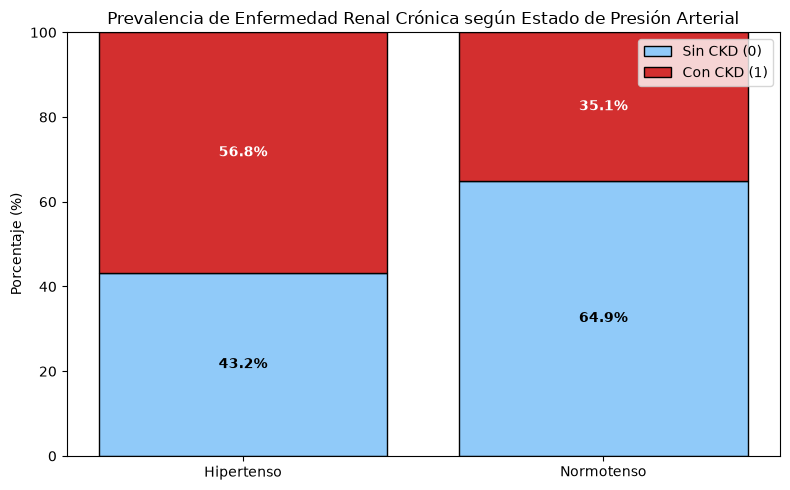

In [30]:
# Filtramos las observaciones con datos completos en las variables de interés
df_presion = df_limpio.dropna(subset=["ckd_present", "bp_systolic", "bp_diastolic"]).copy()
df_presion["ckd_present"] = df_presion["ckd_present"].astype(int)


# pasamos a la creación de la variable categórica según lo explicado, usamos el np.where que funciona como un IF-ELSE si la condicion se cumple asigna el primer string sino el segundo
es_hipertenso = (df_presion["bp_systolic"] >= 130) | (df_presion["bp_diastolic"] >= 80)
df_presion["hipertension"] = np.where(es_hipertenso, "Hipertenso", "Normotenso")


# construimos las tablas de contingencia
# Frecuencias observadas 
tabla_contingencia = pd.crosstab(
    df_presion["hipertension"],
    df_presion["ckd_present"],
    rownames=["Condición de Presión"],
    colnames=["CKD Presente"]
)
# Porcentajes calculados por fila 
tabla_porcentajes = pd.crosstab(
    df_presion["hipertension"],
    df_presion["ckd_present"],
    normalize="index"
) * 100



print("Tabla de contingencia (Frecuencias observadas):")
display(tabla_contingencia)
print("\nPrevalencia por condición (% por fila):")
display(tabla_porcentajes.round(2))



# teniendo las tablas de contingencia pasamos a hacer el Test Chi-cuadrado de independencia
chi2_stat, p_val, dof, frec_esperadas = stats.chi2_contingency(tabla_contingencia)


# Métricas de asociación y riesgo que explicamos arriba
a = tabla_contingencia.loc["Hipertenso", 1]
b = tabla_contingencia.loc["Hipertenso", 0]
c = tabla_contingencia.loc["Normotenso", 1]
d = tabla_contingencia.loc["Normotenso", 0]
riesgo_relativo = (a / (a + b)) / (c / (c + d))
odds_ratio = (a * d) / (b * c)
print(f"\nResultados del Test Chi-cuadrado:")
print(f"Estadístico Chi2: {chi2_stat:.2f}")
print(f"Grados de libertad: {dof}")
print(f"p-valor: {p_val:.4e}")
print(f"\nMedidas de riesgo:")
print(f"Riesgo Relativo (RR): {riesgo_relativo:.2f}")
print(f"Odds Ratio (OR): {odds_ratio:.2f}")


#visualiacion mediante graficos de barras
fig, ax = plt.subplots(figsize=(8, 5))
bar_sano = ax.bar(tabla_porcentajes.index, tabla_porcentajes[0], label="Sin CKD (0)", color="#90caf9", edgecolor="black")
bar_ckd = ax.bar(tabla_porcentajes.index, tabla_porcentajes[1], bottom=tabla_porcentajes[0], label="Con CKD (1)", color="#d32f2f", edgecolor="black")

for bar in bar_sano:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h/2, f"{h:.1f}%", ha="center", va="center", color="black", fontweight="bold")
for bar in bar_ckd:
    h = bar.get_height()
    y_base = bar.get_y()
    ax.text(bar.get_x() + bar.get_width()/2, y_base + h/2, f"{h:.1f}%", ha="center", va="center", color="white", fontweight="bold")
ax.set_ylabel("Porcentaje (%)")
ax.set_title("Prevalencia de Enfermedad Renal Crónica según Estado de Presión Arterial")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

La proporción de casos identificados de ERC fue del 56,82 % en el grupo clasificado con presión elevada y del 35,07 % en el grupo por debajo de ambos umbrales.

El test arrojó χ² = 278,30, con 1 grado de libertad y p = 1,76 × 10⁻⁶². Como el p-valor es menor que 0,05, rechazamos la hipótesis nula de independencia.

El cociente entre las proporciones observadas fue 1,62, equivalente a una prevalencia relativa un 62 % mayor en el grupo de presión elevada. La razón de odds fue 2,44.

Estos resultados respaldan una asociación entre la clasificación de presión arterial y la presencia de ERC en los registros analizados. El carácter transversal de los datos limita la interpretación sobre la dirección temporal y la causalidad de esa asociación.

### Análisis de la hipótesis multivariada planteada por la cátedra

La hipótesis plantea un vínculo entre edad, sexo, IMC, presión arterial, diabetes, tabaquismo, nivel socioeconómico y la probabilidad de presentar CKD.

Para abordarla preparamos el subconjunto de casos completos, examinamos las correlaciones entre las variables y utilizamos PCA para describir su estructura. Después ajustamos una regresión logística y evaluamos su desempeño en un conjunto de test.

Los coeficientes del modelo permiten describir la dirección de las asociaciones estimadas al considerar conjuntamente los predictores.


Seleccionamos los registros con datos completos en las variables del enunciado y conservamos los códigos válidos de diabetes. Codificamos sexo masculino como 1 y femenino como 0. Agrupamos diabetes y diagnóstico límite en la categoría 1, frente a ausencia de diagnóstico (0). El antecedente de haber fumado al menos 100 cigarrillos se representa mediante 1 y su ausencia mediante 0.


In [102]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# seleccionamos las columnas que menciona la hipotesis
columnas_modelo = [
    "age", "gender", "bmi", "bp_systolic", "bp_diastolic",
    "diabetes_diagnosed", "ever_smoked", "poverty_income_ratio", "ckd_present"
]

# quitamos nulos y nos quedamos con los codigos validos de diabetes (1=Si, 2=No, 3=Limite)
df_modelo = df_limpio[columnas_modelo].dropna().copy()
df_modelo = df_modelo[df_modelo["diabetes_diagnosed"].isin([1, 2, 3])].copy()

# pasamos las categoricas y booleanas a 0 y 1 para poder analizarlas numericamente
df_modelo["gender_bin"] = (df_modelo["gender"] == "Male").astype(int)
df_modelo["diabetes_bin"] = df_modelo["diabetes_diagnosed"].isin([1, 3]).astype(int)
df_modelo["tabaquismo_bin"] = df_modelo["ever_smoked"].astype(int)
df_modelo["ckd_present"] = df_modelo["ckd_present"].astype(int)

features = [
    "age", "gender_bin", "bmi", "bp_systolic", "bp_diastolic",
    "diabetes_bin", "tabaquismo_bin", "poverty_income_ratio"
]
nombres_features = [
    "Edad", "Sexo (Masculino)", "BMI", "Presion Sistolica", "Presion Diastolica",
    "Diabetes", "Tabaquismo", "Nivel Socioeconomico (PIR)"
]

X = df_modelo[features].astype(float)
y = df_modelo["ckd_present"]

print("Cantidad de registros limpios:", len(df_modelo))
print("Distribucion de ckd_present (0 = Sin CKD, 1 = Con CKD):")
print(y.value_counts())

Cantidad de registros limpios: 4738
Distribucion de ckd_present (0 = Sin CKD, 1 = Con CKD):
ckd_present
0    2518
1    2220
Name: count, dtype: int64


Examinamos las correlaciones de Pearson mediante un mapa de calor. Esto permite describir asociaciones lineales entre las variables y reconocer predictores que comparten información, aspecto relevante para el PCA y la estimación conjunta de los coeficientes de la regresión.


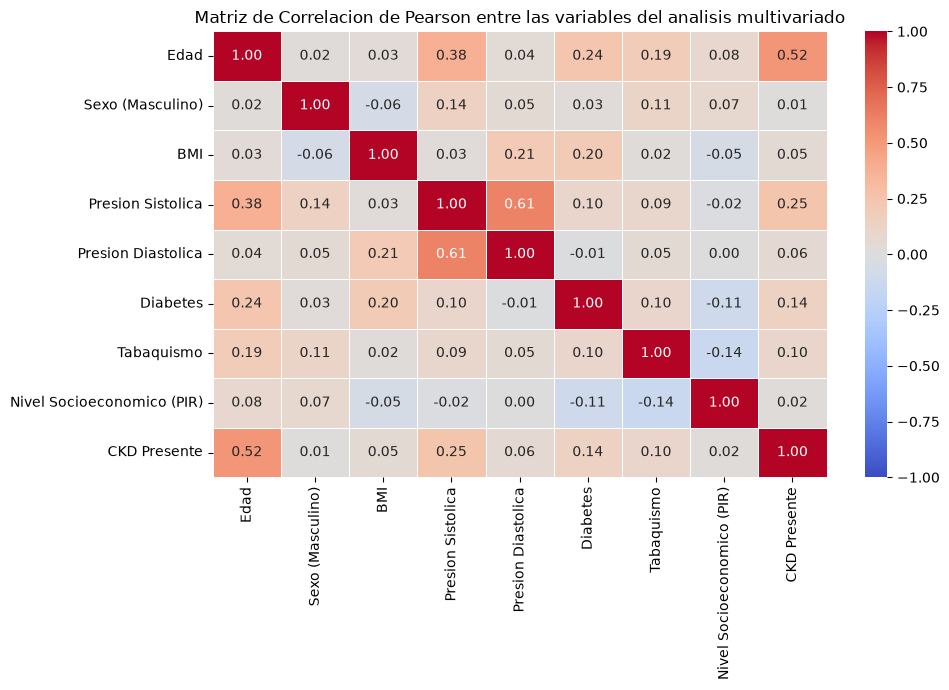

In [103]:
# armamos un dataframe con nombres claros incluyendo la variable objetivo para ver todas las correlaciones
df_corr = X.copy()
df_corr.columns = nombres_features
df_corr["CKD Presente"] = y.values

matriz_corr = df_corr.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlacion de Pearson entre las variables del analisis multivariado")
plt.tight_layout()
plt.show()

Las correlaciones individuales positivas más altas con la etiqueta CKD corresponden a edad (aproximadamente 0,52), presión sistólica (0,25), diabetes (0,14) y antecedente de tabaquismo (0,10).

Entre los predictores se observa una correlación de aproximadamente 0,61 entre ambas presiones. La edad también se relaciona con la sistólica (0,38), diabetes (0,24) y tabaquismo (0,19).

A continuación aplicamos PCA a los predictores estandarizados para examinar la varianza explicada y representar parte de su estructura en un biplot.


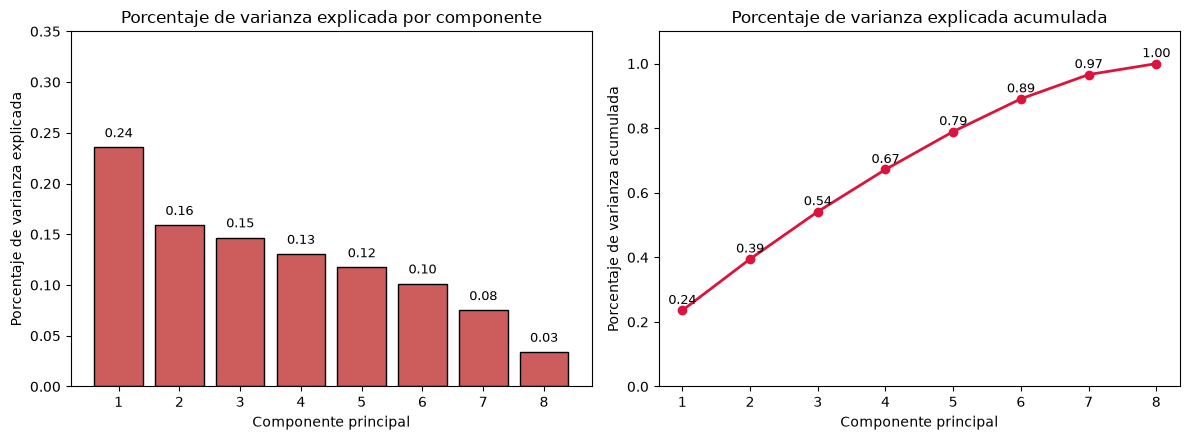

Aporte (cargas) de cada variable a las primeras 3 componentes principales:


,Edad,Sexo (Masculino),BMI,Presion Sistolica,Presion Diastolica,Diabetes,Tabaquismo,Nivel Socioeconomico (PIR)
PC1,0.414,0.151,0.211,0.611,0.510,0.259,0.243,-0.041
PC2,0.179,-0.201,0.299,-0.281,-0.358,0.569,0.336,-0.440
PC3,-0.386,-0.460,0.545,0.018,0.383,-0.041,-0.371,-0.236


In [104]:
# estandarizamos todas las variables predictoras antes de aplicar PCA 
scaler_pca = StandardScaler()
X_pca_stand = scaler_pca.fit_transform(X)

pca = PCA()
componentes = pca.fit_transform(X_pca_stand)

var_explicada = pca.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

# graficamos la varianza explicada por componente y la acumulada 
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

ejes[0].bar(range(1, len(var_explicada) + 1), var_explicada, color="indianred", edgecolor="black")
for i, v in enumerate(var_explicada):
    ejes[0].text(i + 1, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ejes[0].set_xlabel("Componente principal")
ejes[0].set_ylabel("Porcentaje de varianza explicada")
ejes[0].set_title("Porcentaje de varianza explicada por componente")
ejes[0].set_ylim(0, 0.35)

ejes[1].plot(range(1, len(var_acumulada) + 1), var_acumulada, marker="o", color="crimson", linewidth=2)
for i, v in enumerate(var_acumulada):
    ejes[1].text(i + 1, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
ejes[1].set_xlabel("Componente principal")
ejes[1].set_ylabel("Porcentaje de varianza acumulada")
ejes[1].set_title("Porcentaje de varianza explicada acumulada")
ejes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

# mostramos la tabla de cargas de las primeras 3 componentes
tabla_cargas = pd.DataFrame(
    pca.components_[:3],
    columns=nombres_features,
    index=["PC1", "PC2", "PC3"]
)
print("Aporte (cargas) de cada variable a las primeras 3 componentes principales:")
display(tabla_cargas.round(3))

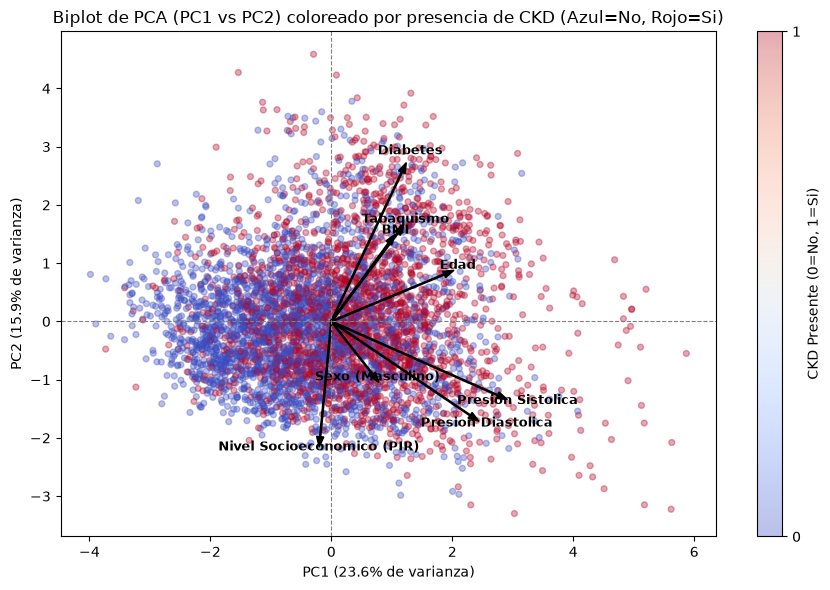

In [105]:
# graficamos el Biplot en el plano de las 2 primeras componentes pintando por CKD Presente
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    componentes[:, 0], componentes[:, 1],
    c=y, cmap="coolwarm", alpha=0.35, s=18
)

# superponemos las flechas de las variables originales
escala_flechas = 4.5
for i, nombre in enumerate(nombres_features):
    dx = pca.components_[0, i] * escala_flechas
    dy = pca.components_[1, i] * escala_flechas
    plt.arrow(0, 0, dx, dy, color="black", width=0.02, head_width=0.12)
    plt.text(dx * 1.12, dy * 1.12, nombre, color="black", fontsize=9, fontweight="bold", ha="center")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel(f"PC1 ({var_explicada[0]*100:.1f}% de varianza)")
plt.ylabel(f"PC2 ({var_explicada[1]*100:.1f}% de varianza)")
plt.title("Biplot de PCA (PC1 vs PC2) coloreado por presencia de CKD (Azul=No, Rojo=Si)")
plt.colorbar(scatter, ticks=[0, 1], label="CKD Presente (0=No, 1=Si)")
plt.tight_layout()
plt.show()

Las dos primeras componentes principales explican aproximadamente el 39,5 % de la varianza total, con 23,6 % en PC1 y 15,9 % en PC2. Con cinco componentes se alcanza aproximadamente el 79 %. Para este modelo decidimos conservar las ocho variables originales, dado que una representación de solo dos componentes retendría una fracción limitada de la variabilidad.

En PC1, edad, ambas presiones, IMC, diabetes y tabaquismo presentan pesos positivos, mientras que la razón ingreso/pobreza presenta un peso negativo. El biplot permite explorar estas relaciones dentro del plano que representan las dos primeras componentes.

Para evaluar la clasificación de CKD utilizamos una regresión logística. Separamos entrenamiento (80 %) y test (20 %) con estratificación por la respuesta. El escalador se ajusta en entrenamiento y se aplica al test. Luego utilizamos GridSearchCV para seleccionar C con regularización L2 y evaluamos el modelo elegido en el test reservado.


Mejor hiperparametro C seleccionado por validacion cruzada: 0.01
Exactitud (Accuracy) en test: 0.6983 (69.83%)
Tasa de error en test: 0.3017


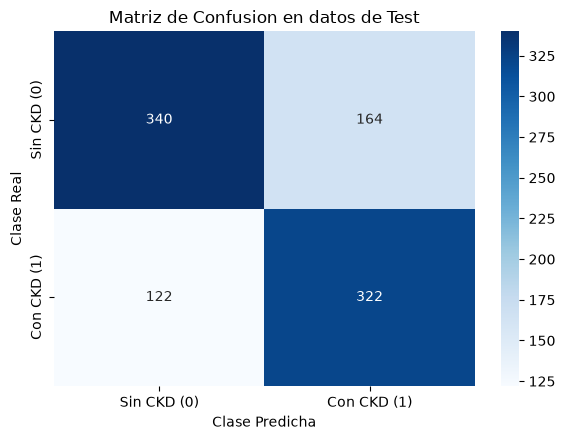

In [106]:
# dividimos en train y test (80% / 20%) manteniendo la proporcion de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=10
)

# estandarizamos ajustando el scaler unicamente con los datos de entrenamiento
scaler = StandardScaler()
scaler.fit(X_train)

X_train_stand = scaler.transform(X_train)
X_test_stand = scaler.transform(X_test)

# como vimos que hay colinealidad entre las presiones y la edad, probamos GridSearchCV con regularizacion L2 
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=10),
    param_grid, cv=5, scoring="accuracy"
)
grid_search.fit(X_train_stand, y_train)
best_logistic_model = grid_search.best_estimator_

# predecimos sobre los datos de test estandarizados
y_pred = best_logistic_model.predict(X_test_stand)

# calculamos exactitud y matriz de confusion
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Mejor hiperparametro C seleccionado por validacion cruzada:", grid_search.best_params_["C"])
print(f"Exactitud (Accuracy) en test: {acc:.4f} ({acc*100:.2f}%)")
print("Tasa de error en test:", round(1 - acc, 4))

# graficamos la matriz de confusion
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Sin CKD (0)", "Con CKD (1)"],
    yticklabels=["Sin CKD (0)", "Con CKD (1)"]
)
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.title("Matriz de Confusion en datos de Test")
plt.tight_layout()
plt.show()

Representamos los coeficientes estimados por la regresión logística. Como los predictores se estandarizaron, cada coeficiente expresa el cambio estimado en el logaritmo de las odds de CKD por una desviación estándar adicional del predictor, manteniendo constantes los demás. Para los indicadores binarios, la comparación entre categorías requiere considerar la escala aplicada durante la estandarización.


,Variable,Coeficiente
0,Edad,1.0900
3,Presion Sistolica,0.1875
2,BMI,0.0492
5,Diabetes,0.0435
6,Tabaquismo,0.0116
4,Presion Diastolica,-0.0025
7,Nivel Socioeconomico (PIR),-0.0074
1,Sexo (Masculino),-0.0105


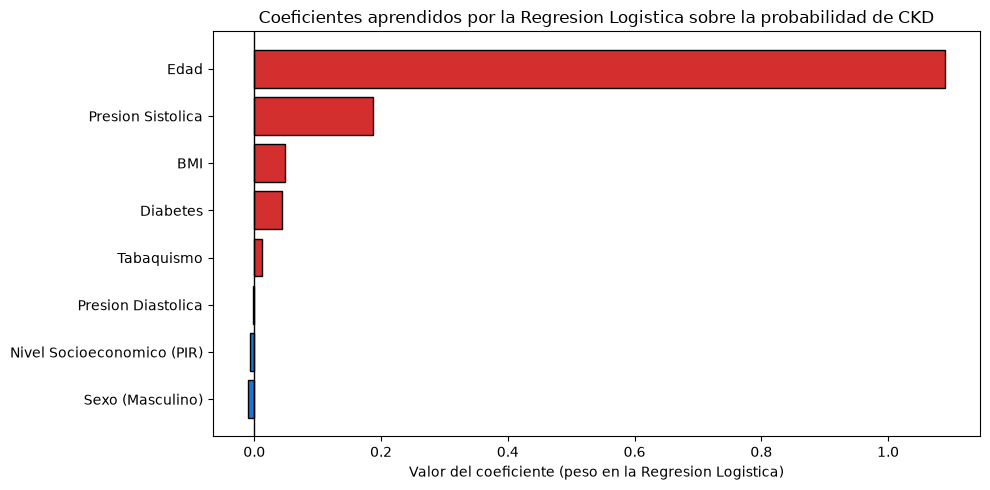

In [107]:
# recuperamos los coeficientes del mejor modelo logistico
theta_logistic = best_logistic_model.coef_[0]

tabla_coeficientes = pd.DataFrame({
    "Variable": nombres_features,
    "Coeficiente": theta_logistic
}).sort_values(by="Coeficiente", ascending=False)

display(tabla_coeficientes.round(4))

# graficamos los coeficientes aprendidos
fig, ax = plt.subplots(figsize=(10, 5))
colores_coef = ["#d32f2f" if c > 0 else "#1976d2" for c in tabla_coeficientes["Coeficiente"]]
ax.barh(tabla_coeficientes["Variable"][::-1], tabla_coeficientes["Coeficiente"][::-1], color=colores_coef[::-1], edgecolor="black")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Valor del coeficiente (peso en la Regresion Logistica)")
ax.set_title("Coeficientes aprendidos por la Regresion Logistica sobre la probabilidad de CKD")
plt.tight_layout()
plt.show()

El modelo logístico alcanzó una exactitud del 69,83 % en los 948 registros del conjunto de test, con una tasa de error del 30,17 %. La matriz de confusión permite examinar cómo se distribuyen los aciertos y errores entre las dos clases.

Los coeficientes estimados fueron positivos para edad (1,0900), presión sistólica (0,1875), IMC (0,0492), diabetes o diagnóstico límite (0,0435) y antecedente de tabaquismo (0,0116). Sus signos describen asociaciones positivas estimadas al considerar conjuntamente las demás variables. Los coeficientes de presión diastólica (−0,0025), razón ingreso/pobreza (−0,0074) y sexo masculino (−0,0105) fueron negativos.

Las correlaciones entre predictores y la regularización L2 influyen en la estimación conjunta de estos pesos. Un coeficiente pequeño debe interpretarse dentro del ajuste realizado. La significancia estadística individual requiere contrastes o intervalos de confianza que no se calcularon en este análisis.

**La hipótesis recibe respaldo parcial en su alcance predictivo. La combinación de los factores permitió clasificar la etiqueta renal en test con una exactitud del 69,83 %.**

La interpretación se limita a los 4.738 casos completos utilizados. El antecedente de tabaquismo representa haber fumado al menos 100 cigarrillos durante la vida. La metadata también indica que eGFR se calcula utilizando creatinina, edad y sexo, relación que debe tenerse en cuenta al interpretar las asociaciones con la etiqueta renal. Los resultados se calcularon sin ponderaciones poblacionales.
